# LOSO con sEMG + captura de movimiento (MVNX) — CPC–xLSTM a 12 Hz

**Proyecto Integrador — Equipo 1**

En `07_LOSO_CPC_fs12.ipynb` la mejor configuración (sLSTM, horizonte de 1 s, negativos del mismo sujeto, representación `c_T`, ajuste fino preentrenado) llegó a un **F1 macro de 0.437 ± 0.066** entre sujetos. Su sección 10 concluyó que el límite está en la señal: CPC predice bien la sEMG, pero **la sEMG del brazo no contiene la postura** que separa las actividades más confundidas (PT, LT, W y PF). `07_Sincronizacion_sEMG_MVNX.ipynb` ya alineó la sEMG con la captura de movimiento Xsens en una rejilla común de 12 Hz.

Este notebook es una **prueba acotada**: entrena **sólo la combinación ganadora** del 07_LOSO, pero con la sEMG **más** un conjunto pequeño de variables MVNX como entrada, y la compara sujeto por sujeto con la sEMG sola.

## Pregunta

¿Agregar información de postura y movimiento (MVNX) a la entrada mejora el F1 macro en personas nuevas, de forma consistente entre sujetos, y en particular en las actividades que la sEMG confunde?

## Diseño

| Elemento | Decisión | Por qué |
|---|---|---|
| Modelo | El del 07_LOSO, **sin cambios**, salvo el número de canales de entrada (8 → 8 + 30) | Si mejora, la mejora se debe a la información nueva y no a la arquitectura |
| Fusión | **Temprana**: sEMG y MVNX se concatenan como canales de entrada del encoder | Es el cambio mínimo; una fusión tardía sería un segundo paso |
| Método | Sólo **ajuste fino preentrenado** (CPC + ajuste fino) | Fue el mejor del 07_LOSO; las sondas y el entrenamiento desde cero se omiten en esta prueba |
| Rondas | Las mismas 12 rondas LOSO (sujetos 1–12), con la misma validación interna; **13 y 14 siguen cerrados** | Comparación emparejada con el 07_LOSO |
| Semillas | `SEEDS = (0,)` | Si la prueba es prometedora, se agrega la semilla 1 |
| Línea base | **sEMG sola**: las predicciones guardadas del 07_LOSO, filtradas a los **mismos ensayos** | No hay que reentrenar; ver sección 5 |
| Variables MVNX | 30 variables derivadas, relativas al cuerpo (sección 3) | Con 10 sujetos de entrenamiento, 782 columnas redundantes invitan al sobreajuste |
| Escalador | Uno por modalidad, **reajustado en cada ronda** con los 10 sujetos de entrenamiento | Igual que el 07_LOSO; el `log1p` de la sEMG no sirve para ángulos ni velocidades con signo |

# 1. Configuración

In [1]:
import copy, json, math, time
from dataclasses import dataclass
from datetime import datetime, timedelta
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display
from scipy.stats import skew, wilcoxon
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, f1_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# ----------------------------- Diseño -----------------------------
TARGET_FS = 12
QUICK = False                          # True = corrida de humo (2 rondas, pocas épocas, carpeta aparte)
CV_SUBJECTS = tuple(range(1, 13))      # sujetos de la validación cruzada
TEST_SUBJECTS = (13, 14)               # reservados para la prueba final: no se usan aquí
SEEDS = (0,)                           # prueba: sólo la semilla 0

# ----------------------------- Configuración congelada (mejor del 07_LOSO a 12 Hz) -----------------------------
KIND = "sLSTM"
HORIZON_S = 1.0
BATCH_MODE = "mismo_sujeto"
REP = "c_T"
MAX_PRED_HEADS = 12
METHOD = "ajuste fino preentrenado"    # el único método que se entrena aquí

# ----------------------------- Entrenamiento (iguales al 07_LOSO) -----------------------------
EPOCHS_MAX, EVAL_EVERY, PATIENCE = 20, 2, 3
BATCH_SIZE, LR, GRAD_CLIP = 128, 5e-4, 1.0
PROBE_TRAIN_MAX = 15_000
FINETUNE_EPOCHS, FINETUNE_PATIENCE, FINETUNE_BATCH = 15, 3, 256
FINETUNE_LR_HEAD, FINETUNE_LR_BACKBONE = 1e-3, 1e-4
SCALER_FIT_POINTS = 250_000
RERUN = False
SEED_DATA = 0
DEVICE_OVERRIDE = None

FOLDS = CV_SUBJECTS
STEPS_CAP = EVAL_CAP = FT_TRAIN_CAP = None
if QUICK:
    FOLDS, SEEDS = (1, 2), (0,)
    EPOCHS_MAX, EVAL_EVERY, PATIENCE = 2, 1, 1
    PROBE_TRAIN_MAX, STEPS_CAP, EVAL_CAP, FT_TRAIN_CAP, FINETUNE_EPOCHS = 2_000, 4, 1_500, 2_000, 1
# ---------------------------------------------------------------------------

if DEVICE_OVERRIDE:
    DEVICE = torch.device(DEVICE_OVERRIDE)
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")

REPO_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
SYNC_DIR = REPO_DIR / "notebooks" / "_cache" / "sync" / f"fs{TARGET_FS}"     # exportación del 07_Sincronizacion
AV2_DIR = REPO_DIR / "notebooks" / "_cache" / "avance2" / f"fs{TARGET_FS}"   # exportación sEMG que usó el 07_LOSO
LOSO_DIR = REPO_DIR / "checkpoints" / f"cpc07_loso_fs{TARGET_FS}"            # predicciones del 07_LOSO (línea base)
TAG = f"fs{TARGET_FS}" + ("_quick" if QUICK else "")
RUN_DIR = REPO_DIR / "checkpoints" / f"cpc08_loso_semg_mvnx_{TAG}"
SUMMARY_CSV = REPO_DIR / "notebooks" / "_cache" / f"cpc08_loso_semg_mvnx_{TAG}_resultados.csv"
LOG_FILE = RUN_DIR / "progreso.log"
RUN_DIR.mkdir(parents=True, exist_ok=True)
for d in (SYNC_DIR / "un_brazo", SYNC_DIR / "bimanual", AV2_DIR, LOSO_DIR):
    assert d.exists(), f"Falta {d.relative_to(REPO_DIR)}"
assert not set(CV_SUBJECTS) & set(TEST_SUBJECTS)

AV2_META = json.loads((AV2_DIR / "metadata.json").read_text())
SYNC_META = json.loads((SYNC_DIR / "metadata.json").read_text())
assert AV2_META["target_fs"] == SYNC_META["target_fs"] == TARGET_FS and AV2_META["label_rule"] == "final_instant"
LABELS = AV2_META["label_order"]
assert SYNC_META["label_order"] == LABELS
WIN, CPC_HOP, SUP_HOP, TAIL = AV2_META["window_len"], AV2_META["cpc_hop"], AV2_META["supervised_hop"], AV2_META["tail_steps"]

def horizons_for(seconds, fs=TARGET_FS, max_heads=MAX_PRED_HEADS):
    n = max(1, int(round(seconds * fs)))
    if n <= max_heads:
        return tuple(range(1, n + 1))
    return tuple(int(k) for k in np.unique(np.round(np.linspace(n / max_heads, n, max_heads)).astype(int)))

HORIZONS = horizons_for(HORIZON_S)

def inner_validation_subject(held_out):
    """El siguiente sujeto de la lista (circular) decide la parada temprana."""
    i = CV_SUBJECTS.index(held_out)
    return CV_SUBJECTS[(i + 1) % len(CV_SUBJECTS)]

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
# Tablas completas: sin recortar el texto de las celdas ni ocultar columnas o filas
pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", None)
LABEL_COLORS = {"N": "#9e9e9e", "LF": "#1f77b4", "K": "#ff7f0e", "PT": "#2ca02c", "LT": "#d62728", "W": "#9467bd", "PF": "#8c564b"}
print("PyTorch:", torch.__version__, "| dispositivo:", DEVICE, "| QUICK:", QUICK)
print("Corridas:", RUN_DIR.relative_to(REPO_DIR))
print(f"Configuración: {KIND} · horizontes {HORIZONS} ({1000 * HORIZONS[-1] / TARGET_FS:.0f} ms) · {BATCH_MODE} · {REP} · "
      f"ventana {WIN} pasos ({WIN / TARGET_FS:.0f} s)")

PyTorch: 2.11.0 | dispositivo: mps | QUICK: False
Corridas: checkpoints/cpc08_loso_semg_mvnx_fs12
Configuración: sLSTM · horizontes (1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12) (1000 ms) · mismo_sujeto · c_T · ventana 48 pasos (4 s)


# 2. Datos: de la exportación sincronizada a ensayos por brazo

La exportación del 07_Sincronizacion tiene dos conjuntos:

- **`un_brazo`** (isocinéticos y MMH a una mano): 8 canales sEMG por ensayo;
- **`bimanual`** (MMH a dos manos): 16 canales sEMG (8 del brazo izquierdo y 8 del derecho) y un solo MVNX.

El 07_LOSO, en cambio, trató **cada archivo sEMG como un ensayo de 8 canales**: un ensayo bimanual eran dos ensayos, uno por brazo. Para usar el mismo modelo y poder compararlos, cada ensayo bimanual se **parte en dos ensayos por brazo** (sección 3.5): cada uno lleva sus 8 canales sEMG, su propia etiqueta sEMG y las variables MVNX del mismo cuerpo, ordenadas respecto a ese brazo (sección 3.3).

Del MVNX sólo se cargan las columnas crudas necesarias para las 30 variables de la sección 3. Además, se guarda una muestra de 20 000 instantes con **todas** las columnas, sólo para la sección 3.1.

### 2.1 Cómo llegan los datos del 07_Sincronizacion

La exportación **no es un DataFrame**. Por cada conjunto (`un_brazo` y `bimanual`) hay tres archivos:

| Archivo | Tipo | Contenido |
|---|---|---|
| `series.npz` | Diccionario de **arreglos NumPy**, sin nombres de columna | Las señales de todos los ensayos concatenadas una tras otra. Todos los arreglos tienen el mismo número de filas, y la fila *t* es el mismo instante en todos |
| `columns.json` | JSON | Los **nombres** de las columnas de `emg` y `mvnx` (y la unidad de cada una) |
| `trials.csv` | Tabla (sí es un DataFrame) | Una fila por ensayo; `offset` y `n_steps` dicen qué filas de `series.npz` le corresponden |

La celda lee solo los encabezados de los arreglos y unas pocas filas, sin cargar los ~1 GB del MVNX. Al final arma un DataFrame con las primeras filas, **sólo para visualizar**: el notebook trabaja con los arreglos.

In [2]:
import zipfile


def npz_contents(path, n_rows=5):
    """Forma, tipo y primeras filas de cada arreglo de un .npz, sin cargarlo completo."""
    out = {}
    with zipfile.ZipFile(path) as zf:
        for name in zf.namelist():
            with zf.open(name) as fh:
                version = np.lib.format.read_magic(fh)
                read_header = np.lib.format.read_array_header_1_0 if version == (1, 0) else np.lib.format.read_array_header_2_0
                shape, fortran, dtype = read_header(fh)
                k, per_row = min(n_rows, shape[0]), int(np.prod(shape[1:], dtype=int))
                head = np.frombuffer(fh.read(k * per_row * dtype.itemsize), dtype=dtype).reshape((k,) + shape[1:])
            out[name.removesuffix(".npy")] = {"shape": shape, "dtype": dtype, "head": head}
    return out


ARRAY_INFO = {
    "time_s": "tiempo de cada instante (s, reloj MVNX)",
    "emg": "sEMG Norm_RMS (%MVC): 8 canales (un brazo) o 16 (L + R)",
    "mvnx": "las 782 columnas MVNX (NaN donde la grabación no tiene la variable)",
    "label_mvnx": "etiqueta MVNX de cada instante (0–6, −1 = sin etiqueta)",
    "label_emg": "etiqueta sEMG de cada instante",
    "label_emg_L": "etiqueta sEMG del brazo izquierdo",
    "label_emg_R": "etiqueta sEMG del brazo derecho",
    "labels_agree": "True si todas las etiquetas presentes coinciden",
    "offsets": "fila donde empieza cada ensayo (+ el total al final)",
}

for conjunto in ("un_brazo", "bimanual"):
    base = SYNC_DIR / conjunto
    arrays = npz_contents(base / "series.npz")
    cols = json.loads((base / "columns.json").read_text())
    tr = pd.read_csv(base / "trials.csv")
    print(f"══════════ {conjunto} ══════════  ({base.relative_to(REPO_DIR)})")

    print("\nseries.npz — arreglos:")
    display(pd.DataFrame([{"arreglo": k, "forma": v["shape"], "tipo": str(v["dtype"]), "contenido": ARRAY_INFO.get(k, "")}
                          for k, v in arrays.items()]).set_index("arreglo"))

    emg_names, mv_names = [c["name"] for c in cols["emg"]], [c["name"] for c in cols["mvnx"]]
    fields = pd.Series([n.split("__")[0] for n in mv_names]).value_counts(sort=False)
    print(f"columns.json — emg: {len(emg_names)} nombres: {', '.join(emg_names)}")
    print(f"columns.json — mvnx: {len(mv_names)} nombres, formato <campo>__<segmento o articulación>__<componente>, por ejemplo:")
    print("   ", ", ".join(mv_names[:3]), "...", ", ".join(n for n in mv_names if n.startswith("jointAngle__jLeftElbow")))
    print("   columnas por campo:", ", ".join(f"{f} {n}" for f, n in fields.items()))

    print(f"\ntrials.csv — {len(tr)} ensayos × {tr.shape[1]} columnas:")
    display(tr.head(3))

    show_mv = ["position__Pelvis__z", "jointAngle__jLeftElbow__c3", "jointAngle__jRightElbow__c3"]
    view = pd.DataFrame({"time_s": arrays["time_s"]["head"]})
    for i, n in enumerate(emg_names[:3]):
        view[n] = arrays["emg"]["head"][:, i]
    for n in show_mv:
        view[n] = arrays["mvnx"]["head"][:, mv_names.index(n)]
    for k in [k for k in arrays if k.startswith("label")]:
        view[k] = arrays[k]["head"]
    print(f"Primeras filas como DataFrame (sólo algunas de las {len(emg_names)} + {len(mv_names)} columnas), "
          f"ensayo {tr.iloc[0]['mvnx_file']}:")
    display(view)
    print()

══════════ un_brazo ══════════  (notebooks/_cache/sync/fs12/un_brazo)

series.npz — arreglos:


,forma,tipo,contenido
arreglo,,,
time_s,"(244388,)",float64,"tiempo de cada instante (s, reloj MVNX)"
emg,"(244388, 8)",float32,sEMG Norm_RMS (%MVC): 8 canales (un brazo) o 16 (L + R)
mvnx,"(244388, 782)",float32,las 782 columnas MVNX (NaN donde la grabación no tiene la variable)
label_mvnx,"(244388,)",int8,"etiqueta MVNX de cada instante (0–6, −1 = sin etiqueta)"
labels_agree,"(244388,)",bool,True si todas las etiquetas presentes coinciden
label_emg,"(244388,)",int8,etiqueta sEMG de cada instante
offsets,"(384,)",int64,fila donde empieza cada ensayo (+ el total al final)


columns.json — emg: 8 nombres: Norm_RMS_1, Norm_RMS_2, Norm_RMS_3, Norm_RMS_4, Norm_RMS_5, Norm_RMS_6, Norm_RMS_7, Norm_RMS_8
columns.json — mvnx: 782 nombres, formato <campo>__<segmento o articulación>__<componente>, por ejemplo:
    position__Pelvis__x, position__Pelvis__y, position__Pelvis__z ... jointAngle__jLeftElbow__c1, jointAngle__jLeftElbow__c2, jointAngle__jLeftElbow__c3
   columnas por campo: position 69, velocity 69, acceleration 69, angularVelocity 69, angularAcceleration 69, sensorFreeAcceleration 51, sensorMagneticField 51, centerOfMass 3, jointAngle 66, jointAngleXZY 66, jointAngleErgo 18, jointAngleErgoXZY 18, orientation 92, sensorOrientation 68, footContacts 4

trials.csv — 383 ensayos × 25 columnas:


,trial_idx,mvnx_file,subject,task,side,load_kg,condition,split,offset,n_steps,duration_s,fs_mv_real,validacion_dudosa,emg_file_L,fs_emg_L,desfase_eventos_L_s,desfase_senal_L_s,correlacion_senal_L,residuo_p95_L_ms,emg_file_R,fs_emg_R,desfase_eventos_R_s,desfase_senal_R_s,correlacion_senal_R,residuo_p95_R_ms
0,0,Subj_01_Isokin_L_02kg_40bpm.mvnx,1,Isokin,L,2,40bpm,train,0,767,63.895,240.003130,False,Subj_01_Isokin_L_02kg_40bpm_EMG_data.csv,692.828148,8.928635,8.75,0.558401,1.110986,NaN,NaN,NaN,NaN,NaN,NaN
1,1,Subj_01_Isokin_L_02kg_60bpm.mvnx,1,Isokin,L,2,60bpm,train,767,792,65.933,240.001213,False,Subj_01_Isokin_L_02kg_60bpm_EMG_data.csv,757.816812,9.569240,10.15,0.691434,1.235864,NaN,NaN,NaN,NaN,NaN,NaN
2,2,Subj_01_Isokin_L_02kg_80bpm.mvnx,1,Isokin,L,2,80bpm,train,1559,670,55.754,240.000717,True,Subj_01_Isokin_L_02kg_80bpm_EMG_data.csv,732.999328,5.805385,-0.20,0.721625,1.204077,NaN,NaN,NaN,NaN,NaN,NaN


Primeras filas como DataFrame (sólo algunas de las 8 + 782 columnas), ensayo Subj_01_Isokin_L_02kg_40bpm.mvnx:


...

,forma,tipo,contenido
arreglo,,,
time_s,"(90819,)",float64,"tiempo de cada instante (s, reloj MVNX)"
emg,"(90819, 16)",float32,sEMG Norm_RMS (%MVC): 8 canales (un brazo) o 16 (L + R)
mvnx,"(90819, 782)",float32,las 782 columnas MVNX (NaN donde la grabación no tiene la variable)
label_mvnx,"(90819,)",int8,"etiqueta MVNX de cada instante (0–6, −1 = sin etiqueta)"
label_emg_L,"(90819,)",int8,etiqueta sEMG del brazo izquierdo
label_emg_R,"(90819,)",int8,etiqueta sEMG del brazo derecho
labels_agree,"(90819,)",bool,True si todas las etiquetas presentes coinciden
offsets,"(123,)",int64,fila donde empieza cada ensayo (+ el total al final)


columns.json — emg: 16 nombres: L_Norm_RMS_1, L_Norm_RMS_2, L_Norm_RMS_3, L_Norm_RMS_4, L_Norm_RMS_5, L_Norm_RMS_6, L_Norm_RMS_7, L_Norm_RMS_8, R_Norm_RMS_1, R_Norm_RMS_2, R_Norm_RMS_3, R_Norm_RMS_4, R_Norm_RMS_5, R_Norm_RMS_6, R_Norm_RMS_7, R_Norm_RMS_8
columns.json — mvnx: 782 nombres, formato <campo>__<segmento o articulación>__<componente>, por ejemplo:
    position__Pelvis__x, position__Pelvis__y, position__Pelvis__z ... jointAngle__jLeftElbow__c1, jointAngle__jLeftElbow__c2, jointAngle__jLeftElbow__c3
   columnas por campo: position 69, velocity 69, acceleration 69, angularVelocity 69, angularAcceleration 69, sensorFreeAcceleration 51, sensorMagneticField 51, centerOfMass 3, jointAngle 66, jointAngleXZY 66, jointAngleErgo 18, jointAngleErgoXZY 18, orientation 92, sensorOrientation 68, footContacts 4

trials.csv — 122 ensayos × 25 columnas:


,trial_idx,mvnx_file,subject,task,side,load_kg,condition,split,offset,n_steps,duration_s,fs_mv_real,validacion_dudosa,emg_file_L,fs_emg_L,desfase_eventos_L_s,desfase_senal_L_s,correlacion_senal_L,residuo_p95_L_ms,emg_file_R,fs_emg_R,desfase_eventos_R_s,desfase_senal_R_s,correlacion_senal_R,residuo_p95_R_ms
0,0,Subj_01_MMH_Bim_02kg_Trial_1.mvnx,1,MMH_Bim,LR,2,Trial_1,train,0,750,62.444000,240.007046,False,Subj_01_MMH_Bim_L_02kg_Trial_1_EMG_data.csv,900.417720,8.678115,9.50,0.665727,0.857568,Subj_01_MMH_Bim_R_02kg_Trial_1_EMG_data.csv,923.979195,10.050960,10.4,0.554529,0.843555
1,1,Subj_01_MMH_Bim_02kg_Trial_2.mvnx,1,MMH_Bim,LR,2,Trial_2,train,750,811,67.522340,240.001769,False,Subj_01_MMH_Bim_L_02kg_Trial_2_EMG_data.csv,891.597748,7.846850,8.75,0.696261,0.767944,Subj_01_MMH_Bim_R_02kg_Trial_2_EMG_data.csv,910.222216,9.812915,10.1,0.731193,0.940027
2,2,Subj_01_MMH_Bim_02kg_Trial_3.mvnx,1,MMH_Bim,LR,2,Trial_3,train,1561,792,65.939055,240.004108,False,Subj_01_MMH_Bim_L_02kg_Trial_3_EMG_data.csv,788.450462,6.924115,7.35,0.739875,1.002087,Subj_01_MMH_Bim_R_02kg_Trial_3_EMG_data.csv,797.663049,7.796050,8.0,0.772209,1.191443


Primeras filas como DataFrame (sólo algunas de las 16 + 782 columnas), ensayo Subj_01_MMH_Bim_02kg_Trial_1.mvnx:


,time_s,L_Norm_RMS_1,L_Norm_RMS_2,L_Norm_RMS_3,position__Pelvis__z,jointAngle__jLeftElbow__c3,jointAngle__jRightElbow__c3,label_mvnx,label_emg_L,label_emg_R,labels_agree
0,0.000000,12.840605,1.399446,0.917721,1.071504,5.444151,15.456138,-1,-1,-1,False
1,0.083333,12.843506,1.461601,0.945004,1.071575,5.472780,15.478169,-1,-1,-1,False
2,0.166667,12.885830,1.564167,0.943135,1.071644,5.499360,15.558902,-1,-1,-1,False
3,0.250000,12.831844,1.608584,0.920347,1.071700,5.538664,15.614674,-1,-1,-1,False
4,0.333333,12.819201,1.545365,0.871189,1.071742,5.559860,15.670764,-1,-1,-1,False


In [3]:
SIDE_NAME = {"L": "Left", "R": "Right"}
OTHER = {"L": "R", "R": "L"}

# Columnas MVNX crudas que se necesitan para calcular las variables de la sección 3
RAW_COLUMNS = (
    [f"position__{s}__{a}" for s in ("Pelvis", "Head", "LeftHand", "RightHand") for a in "xyz"]
    + [f"velocity__{s}__{a}" for s in ("Pelvis", "LeftHand", "RightHand") for a in "xyz"]
    + [f"angularVelocity__{s}__{a}" for s in ("Pelvis", "T8") for a in "xyz"]
    + [f"jointAngle__{j}__c3" for j in ("jL5S1", "jC1Head","jLeftElbow", "jRightElbow", "jLeftWrist", "jRightWrist",
                                       "jLeftHip", "jRightHip", "jLeftKnee", "jRightKnee")]
    + [f"jointAngleXZY__{j}__{c}" for j in ("jLeftShoulder", "jRightShoulder") for c in ("c1", "c3")]
    + [f"footContacts__{f}_{p}" for f in ("LeftFoot", "RightFoot") for p in ("Heel", "Toe")]
)
RAW_IDX = {c: i for i, c in enumerate(RAW_COLUMNS)}


def derive(raw, side):
    """Las 30 variables MVNX (sección 3) a partir de las columnas crudas. `side` es el brazo con sEMG."""
    col = lambda name: raw[:, RAW_IDX[name]].astype(np.float64)
    roles = (("ipsi", SIDE_NAME[side]), ("contra", SIDE_NAME[OTHER[side]]))
    out = {"tronco_flexion": col("jointAngle__jL5S1__c3"), "cuello_flexion": col("jointAngle__jC1Head__c3")}
    for rol, s in roles:
        out[f"{rol}_hombro_flexion"] = col(f"jointAngleXZY__j{s}Shoulder__c3")
        out[f"{rol}_hombro_abduccion"] = col(f"jointAngleXZY__j{s}Shoulder__c1")
        out[f"{rol}_codo_flexion"] = col(f"jointAngle__j{s}Elbow__c3")
        out[f"{rol}_muneca_flexion"] = col(f"jointAngle__j{s}Wrist__c3")
        out[f"{rol}_cadera_flexion"] = col(f"jointAngle__j{s}Hip__c3")
        out[f"{rol}_rodilla_flexion"] = col(f"jointAngle__j{s}Knee__c3")
    out["pelvis_altura"] = col("position__Pelvis__z")
    out["cabeza_altura"] = col("position__Head__z")
    for rol, s in roles:
        out[f"{rol}_mano_altura"] = col(f"position__{s}Hand__z")
        out[f"{rol}_mano_alcance"] = np.hypot(col(f"position__{s}Hand__x") - col("position__Pelvis__x"),
                                              col(f"position__{s}Hand__y") - col("position__Pelvis__y"))
    out["pelvis_vel_horizontal"] = np.hypot(col("velocity__Pelvis__x"), col("velocity__Pelvis__y"))
    out["pelvis_vel_vertical"] = col("velocity__Pelvis__z")
    for rol, s in roles:
        out[f"{rol}_mano_rapidez"] = np.linalg.norm([col(f"velocity__{s}Hand__{a}") for a in "xyz"], axis=0)
    out["pelvis_giro"] = np.abs(col("angularVelocity__Pelvis__z"))
    out["tronco_vel_angular"] = np.linalg.norm([col(f"angularVelocity__T8__{a}") for a in "xyz"], axis=0)
    for rol, s in roles:
        out[f"{rol}_talon"] = col(f"footContacts__{s}Foot_Heel")
        out[f"{rol}_punta"] = col(f"footContacts__{s}Foot_Toe")
    return np.column_stack(list(out.values())).astype(np.float32), list(out)


def feature_unit(name):
    if name.endswith(("flexion", "abduccion")):
        return "°"
    if name.endswith(("altura", "alcance")):
        return "m"
    if name.endswith(("vel_horizontal", "vel_vertical", "rapidez")):
        return "m/s"
    if name.endswith(("giro", "vel_angular")):
        return "rad/s"
    return "0/1"


def load_set(conjunto):
    base = SYNC_DIR / conjunto
    cols = json.loads((base / "columns.json").read_text())
    names = [c["name"] for c in cols["mvnx"]]
    pos = {n: i for i, n in enumerate(names)}
    with np.load(base / "series.npz") as z:
        data = {k: z[k] for k in z.files if k != "mvnx"}
        full = z["mvnx"]
    data["mvnx"] = full[:, [pos[c] for c in RAW_COLUMNS]]
    rows = np.sort(np.random.default_rng(SEED_DATA).choice(len(full), 20_000, replace=False))
    return data, pd.read_csv(base / "trials.csv"), cols, names, full[rows]


raw_sets = {}
rows, emg_parts, mv_parts, lab_parts, time_parts, offsets = [], [], [], [], [], [0]
for conjunto in ("un_brazo", "bimanual"):
    data, tr, cols, names, sample = load_set(conjunto)
    raw_sets[conjunto] = {"data": data, "trials": tr}
    if conjunto == "un_brazo":
        FULL_NAMES, FULL_SAMPLE = names, sample
    emg_names = [c["name"] for c in cols["emg"]]
    for r in tr.itertuples(index=False):
        sl = slice(r.offset, r.offset + r.n_steps)
        for side in (("L", "R") if conjunto == "bimanual" else (r.side,)):
            if conjunto == "bimanual":
                emg = data["emg"][sl][:, [i for i, n in enumerate(emg_names) if n.startswith(f"{side}_")]]
                lab = data[f"label_emg_{side}"][sl]
            else:
                emg, lab = data["emg"][sl], data["label_emg"][sl]
            assert emg.shape[1] == 8
            mv, FEATURES = derive(data["mvnx"][sl], side)
            rows.append({"trial_idx": len(rows), "file": getattr(r, f"emg_file_{side}"), "mvnx_file": r.mvnx_file,
                         "conjunto": conjunto, "subject": r.subject, "task": r.task, "side": side, "load_kg": r.load_kg,
                         "condition": r.condition, "split": r.split, "offset": offsets[-1], "n_steps": r.n_steps,
                         "desfase_s": getattr(r, f"desfase_eventos_{side}_s"), "validacion_dudosa": bool(r.validacion_dudosa)})
            emg_parts.append(emg); mv_parts.append(mv); lab_parts.append(lab); time_parts.append(data["time_s"][sl])
            offsets.append(offsets[-1] + r.n_steps)
del sample, data

trials = pd.DataFrame(rows)
offsets = np.asarray(offsets[:-1])
EMG_NAMES = [f"Norm_RMS_{i}" for i in range(1, 9)]
CHANNELS = EMG_NAMES + FEATURES
N_EMG, N_MV = len(EMG_NAMES), len(FEATURES)
signals_raw = np.concatenate([np.concatenate(emg_parts), np.concatenate(mv_parts)], axis=1).astype(np.float32)
labels_series = np.concatenate(lab_parts).astype(np.int64)
time_series = np.concatenate(time_parts)
N_CH = signals_raw.shape[1]
BINARY = [i for i, n in enumerate(CHANNELS) if feature_unit(n) == "0/1" and i >= N_EMG]
del emg_parts, mv_parts, lab_parts, time_parts
assert not np.isnan(signals_raw).any(), "Hay NaN en las variables elegidas"
assert trials["file"].is_unique

print(f"{len(trials)} ensayos por brazo | {len(signals_raw):,} instantes | {N_CH} canales ({N_EMG} sEMG + {N_MV} MVNX)")
display(trials.groupby(["conjunto", "task"]).agg(ensayos=("file", "size"), sujetos=("subject", "nunique"),
                                               horas=("n_steps", lambda n: n.sum() / TARGET_FS / 3600),
                                               marcados=("validacion_dudosa", "sum")).round(2))

av2_trials = pd.read_csv(AV2_DIR / "trials.csv")
missing = av2_trials[~av2_trials["file"].isin(trials["file"])]
assert trials["file"].isin(av2_trials["file"]).all(), "Hay ensayos sincronizados que no están en el avance 2"
print(f"Ensayos sEMG del avance 2 (07_LOSO): {len(av2_trials)} | sincronizados: {len(trials)} | "
      f"sin MVNX válido: {len(missing)} (excluidos en el 07_Sincronizacion):")
display(missing[["file", "subject", "task"]].reset_index(drop=True))

627 ensayos por brazo | 426,026 instantes | 38 canales (8 sEMG + 30 MVNX)


ensayos  sujetos  horas  marcados
conjunto task                                      
bimanual MMH_Bim      244       14   4.20        46
un_brazo Isokin       220       14   2.73        60
         MMH_One      163       14   2.93        27

Ensayos sEMG del avance 2 (07_LOSO): 638 | sincronizados: 627 | sin MVNX válido: 11 (excluidos en el 07_Sincronizacion):


,file,subject,task
0,Subj_06_MMH_One_L_02kg_Trial_3_EMG_data.csv,6,MMH_One
1,Subj_07_MMH_Bim_L_08kg_Trial_3_EMG_data.csv,7,MMH_Bim
2,Subj_07_MMH_Bim_L_12kg_Trial_1_EMG_data.csv,7,MMH_Bim
3,Subj_07_MMH_Bim_L_12kg_Trial_2_EMG_data.csv,7,MMH_Bim
4,Subj_07_MMH_One_L_04kg_Trial_2_EMG_data.csv,7,MMH_One
5,Subj_09_MMH_One_R_02kg_Trial_3_EMG_data.csv,9,MMH_One
6,Subj_11_Isokin_R_02kg_St_EMG_data.csv,11,Isokin
7,Subj_13_MMH_One_L_04kg_Trial_2_EMG_data.csv,13,MMH_One
8,Subj_14_Isokin_L_02kg_60bpm_EMG_data.csv,14,Isokin
9,Subj_14_MMH_Bim_L_02kg_Trial_1_EMG_data.csv,14,MMH_Bim


# 3. Preparación de las señales: antes y después

Cada subsección muestra **una** transformación, con un gráfico de la señal antes y después y el motivo.

| # | Transformación | Problema que resuelve |
|---|---|---|
| 3.1 | 782 columnas → 30 variables | Redundancia, variables que dependen del laboratorio y columnas con NaN |
| 3.2 | Posiciones y velocidades → magnitudes relativas al cuerpo | La posición x–y y el rumbo dependen de dónde y hacia dónde está la persona, no de la actividad |
| 3.3 | Izquierdo/derecho → **ipsilateral/contralateral** al brazo con sEMG | El mismo canal debe significar lo mismo en todos los ensayos |
| 3.4 | Escalado por modalidad | sEMG muy asimétrica; MVNX con unidades y rangos distintos y colas largas |
| 3.5 | Ensayo bimanual → dos ensayos por brazo | Mantener la entrada de 8 canales sEMG del 07_LOSO |
| 3.6 | Rejilla del avance 2 → rejilla sincronizada | Comprobar que la sEMG es la misma que vio el 07_LOSO |

## 3.1 Selección de variables: de 782 columnas a 30

La exportación MVNX tiene 782 columnas por instante. Usarlas todas sería un problema por tres razones:

1. **Redundancia.** Muchas columnas son la misma información con otra forma. La aceleración es la derivada de la velocidad, y esta de la posición. Los cuaterniones de orientación y los ángulos articulares describen la misma postura. Las 23 posiciones de segmentos se mueven juntas (el gráfico de la izquierda lo muestra: casi todas las columnas tienen otra con la que se correlacionan más de 0.95).
2. **Variables que dependen del laboratorio, no de la actividad.** El campo magnético depende del entorno. La posición x–y y las orientaciones globales dependen de dónde está parada la persona y hacia dónde mira (sección 3.2).
3. **NaN.** Las 24 columnas `jointAngleErgo*` faltan en los sujetos 1, 11 y 13.

Con sólo 10 sujetos de entrenamiento por ronda, tantas entradas redundantes le dan al modelo muchas formas de memorizar a cada persona. Se eligieron **30 variables** con un significado físico claro, agrupadas en cuatro tipos:

- **ángulos articulares (14):** flexión del tronco, del cuello y, de cada lado, flexión y abducción del hombro y flexión del codo, la muñeca, la cadera y la rodilla. En el hombro se usa la secuencia XZY: con la secuencia ZXY, que es la habitual, los ángulos se vuelven inestables cerca de 90° de elevación del brazo (bloqueo de cardán);
- **alturas y alcance (6):** altura de la pelvis, de la cabeza y de cada mano sobre el suelo, y distancia horizontal de cada mano a la pelvis;
- **velocidades (6):** rapidez horizontal y velocidad vertical de la pelvis, rapidez de cada mano, giro de la pelvis y velocidad angular del tronco;
- **contactos con el suelo (4):** talón y punta de cada pie.

Se descartaron dos variables más por redundantes:

- **la altura del centro de masa:** está muy correlacionada con la altura de la pelvis (se muestra abajo);
- **la flexión T9T8 del tronco:** en los datos es idéntica a la flexión L5S1, salvo la escala (r = 1.00), así que sólo se usa la L5S1.

En el gráfico de la derecha, las pocas variables elegidas que todavía superan |r| > 0.95 son las caderas de los dos lados. Se mueven juntas al agacharse, pero se separan al caminar, y esa diferencia es justo lo que se quiere distinguir.

,columnas,decisión,motivo
position,69,parcial,"pelvis, cabeza y manos → alturas y alcance horizontal; x, y absolutos dependen del lugar en el laboratorio"
velocity,69,parcial,pelvis y manos → rapideces (normas) y velocidad vertical de la pelvis
acceleration,69,descartada,derivada de la velocidad: redundante y más ruidosa
angularVelocity,69,parcial,pelvis (giro alrededor de la vertical) y tronco T8 (norma)
angularAcceleration,69,descartada,derivada de la velocidad angular
sensorFreeAcceleration,51,descartada,redundante con la cinemática de los segmentos
sensorMagneticField,51,descartada,"depende del entorno magnético, no del movimiento"
centerOfMass,3,descartada,su altura es casi igual a la de la pelvis
jointAngle,66,parcial,"flexión (c3) de tronco, cuello, codos, muñecas, caderas y rodillas"
jointAngleXZY,66,parcial,hombros: flexión (c3) y abducción (c1); XZY evita el bloqueo de cardán del hombro


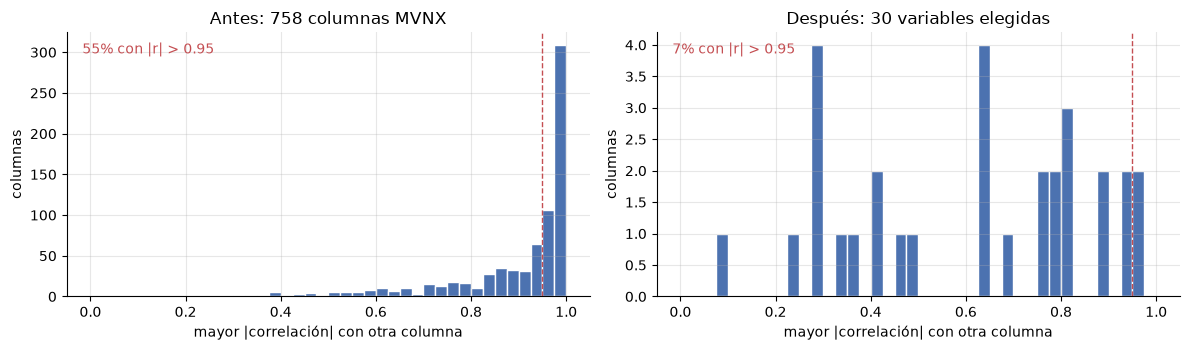

Correlación entre la altura del centro de masa y la de la pelvis: r = 0.979


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29
variable,tronco_flexion,cuello_flexion,ipsi_hombro_flexion,ipsi_hombro_abduccion,ipsi_codo_flexion,ipsi_muneca_flexion,ipsi_cadera_flexion,ipsi_rodilla_flexion,contra_hombro_flexion,contra_hombro_abduccion,contra_codo_flexion,contra_muneca_flexion,contra_cadera_flexion,contra_rodilla_flexion,pelvis_altura,cabeza_altura,ipsi_mano_altura,ipsi_mano_alcance,contra_mano_altura,contra_mano_alcance,pelvis_vel_horizontal,pelvis_vel_vertical,ipsi_mano_rapidez,contra_mano_rapidez,pelvis_giro,tronco_vel_angular,ipsi_talon,ipsi_punta,contra_talon,contra_punta
unidad,°,°,°,°,°,°,°,°,°,°,°,°,°,°,m,m,m,m,m,m,m/s,m/s,m/s,m/s,rad/s,rad/s,0/1,0/1,0/1,0/1


In [4]:
DECISION = {
    "position": ("parcial", "pelvis, cabeza y manos → alturas y alcance horizontal; x, y absolutos dependen del lugar en el laboratorio"),
    "velocity": ("parcial", "pelvis y manos → rapideces (normas) y velocidad vertical de la pelvis"),
    "acceleration": ("descartada", "derivada de la velocidad: redundante y más ruidosa"),
    "angularVelocity": ("parcial", "pelvis (giro alrededor de la vertical) y tronco T8 (norma)"),
    "angularAcceleration": ("descartada", "derivada de la velocidad angular"),
    "sensorFreeAcceleration": ("descartada", "redundante con la cinemática de los segmentos"),
    "sensorMagneticField": ("descartada", "depende del entorno magnético, no del movimiento"),
    "centerOfMass": ("descartada", "su altura es casi igual a la de la pelvis"),
    "jointAngle": ("parcial", "flexión (c3) de tronco, cuello, codos, muñecas, caderas y rodillas"),
    "jointAngleXZY": ("parcial", "hombros: flexión (c3) y abducción (c1); XZY evita el bloqueo de cardán del hombro"),
    "jointAngleErgo": ("descartada", "NaN en los sujetos 1, 11 y 13; redundante con jointAngle"),
    "jointAngleErgoXZY": ("descartada", "NaN en los sujetos 1, 11 y 13; redundante con jointAngle"),
    "orientation": ("descartada", "cuaterniones globales: dependen del rumbo; la postura relativa ya está en los ángulos"),
    "sensorOrientation": ("descartada", "igual que orientation, en los sensores"),
    "footContacts": ("completa", "los 4 contactos (talón y punta de cada pie)"),
}
fields = pd.Series([n.split("__")[0] for n in FULL_NAMES])
display(pd.DataFrame({"columnas": fields.value_counts(sort=False),
                      "decisión": {f: d[0] for f, d in DECISION.items()},
                      "motivo": {f: d[1] for f, d in DECISION.items()}}).reindex(list(DECISION)))


def max_abs_corr(x):
    """Para cada columna, la mayor |correlación| con alguna otra (sin NaN ni columnas constantes)."""
    x = x[:, ~np.isnan(x).any(axis=0)]
    x = x[:, x.std(axis=0) > 0]
    c = np.abs(np.corrcoef(x, rowvar=False))
    np.fill_diagonal(c, 0)
    return c.max(axis=0)


corr_before = max_abs_corr(FULL_SAMPLE.astype(np.float64))
idx_ub = np.concatenate([np.arange(r.offset, r.offset + r.n_steps) for r in trials[trials["conjunto"] == "un_brazo"].itertuples()])
mv_sample = signals_raw[np.random.default_rng(SEED_DATA).choice(idx_ub, 20_000, replace=False), N_EMG:].astype(np.float64)
corr_after = max_abs_corr(mv_sample)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
bins = np.linspace(0, 1, 41)
for ax, values, title in ((axes[0], corr_before, f"Antes: {len(corr_before)} columnas MVNX"),
                          (axes[1], corr_after, f"Después: {N_MV} variables elegidas")):
    ax.hist(values, bins=bins, color="#4c72b0", edgecolor="white")
    ax.axvline(0.95, color="#c44e52", ls="--", lw=1)
    ax.set(xlabel="mayor |correlación| con otra columna", ylabel="columnas", title=title)
    ax.text(0.03, 0.92, f"{(values > 0.95).mean():.0%} con |r| > 0.95", transform=ax.transAxes, color="#c44e52")
plt.tight_layout()
plt.show()

col = {n: i for i, n in enumerate(FULL_NAMES)}
r_com = np.corrcoef(FULL_SAMPLE[:, col["centerOfMass__z"]], FULL_SAMPLE[:, col["position__Pelvis__z"]])[0, 1]
print(f"Correlación entre la altura del centro de masa y la de la pelvis: r = {r_com:.3f}")
display(pd.DataFrame({"variable": FEATURES, "unidad": [feature_unit(n) for n in FEATURES]}).T)

## 3.2 Invariancia a la posición y al rumbo en el laboratorio

**Antes:** la posición del MVNX está en coordenadas del laboratorio. La misma persona empieza cada ensayo en un lugar distinto y camina en direcciones distintas, así que la posición x de la mano cambia de un ensayo a otro aunque haga lo mismo (arriba al centro). Lo mismo pasa con las componentes x e y de la velocidad: el signo depende de hacia dónde camina (abajo).

**Después:** se usan magnitudes que no dependen de dónde ni hacia dónde está la persona:

- el **alcance**, que es la distancia horizontal de la mano a la pelvis (arriba a la derecha);
- la **rapidez horizontal** de la pelvis, es decir, la norma de (vx, vy);
- las **alturas** (z), que sí son comparables, porque el suelo está en z = 0 en todos los ensayos.

Así el modelo no puede usar el lugar del laboratorio como pista. Esa pista no existiría en una persona nueva, ni en un lugar distinto.

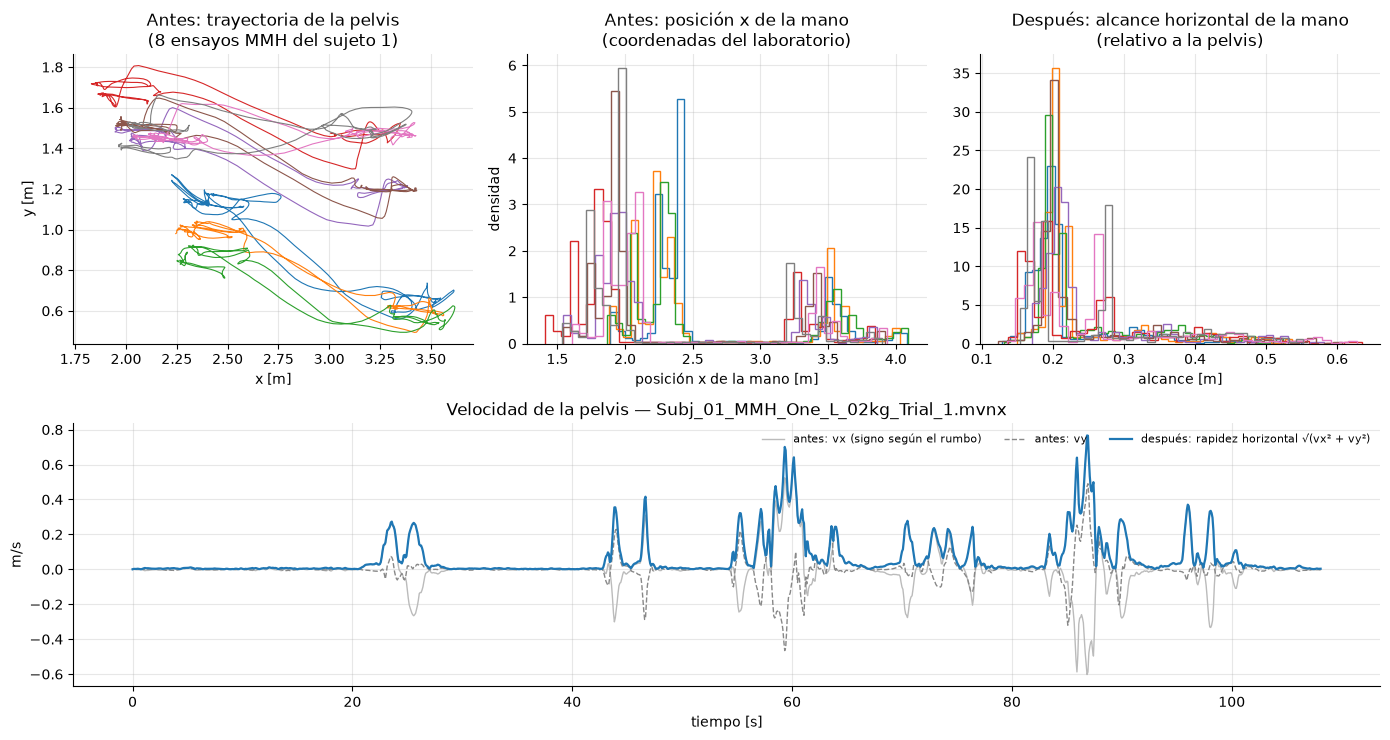

Variación de la mediana entre los 8 ensayos (desv. estándar): {'posición x de la mano': '0.195 m', 'alcance de la mano': '0.006 m'}


In [5]:
ub_raw, ub_tr = raw_sets["un_brazo"]["data"]["mvnx"], raw_sets["un_brazo"]["trials"]
example_trials = ub_tr[(ub_tr["subject"] == 1) & (ub_tr["task"] == "MMH_One")].head(8)
R = lambda sl, name: ub_raw[sl, RAW_IDX[name]]

fig, axes = plt.subplot_mosaic([["xy", "antes", "despues"], ["vel", "vel", "vel"]], figsize=(14, 7.5),
                               gridspec_kw={"height_ratios": [1.1, 1]})
spread = {"posición x de la mano": [], "alcance de la mano": []}
for k, r in enumerate(example_trials.itertuples()):
    sl, hand, color = slice(r.offset, r.offset + r.n_steps), SIDE_NAME[r.side] + "Hand", f"C{k}"
    axes["xy"].plot(R(sl, "position__Pelvis__x"), R(sl, "position__Pelvis__y"), color=color, lw=0.8)
    hand_x = R(sl, f"position__{hand}__x")
    reach = np.hypot(hand_x - R(sl, "position__Pelvis__x"), R(sl, f"position__{hand}__y") - R(sl, "position__Pelvis__y"))
    axes["antes"].hist(hand_x, bins=40, histtype="step", color=color, density=True)
    axes["despues"].hist(reach, bins=40, histtype="step", color=color, density=True)
    spread["posición x de la mano"].append(np.median(hand_x))
    spread["alcance de la mano"].append(np.median(reach))
axes["xy"].set(xlabel="x [m]", ylabel="y [m]", title="Antes: trayectoria de la pelvis\n(8 ensayos MMH del sujeto 1)")
axes["xy"].set_aspect("equal", adjustable="datalim")
axes["antes"].set(xlabel="posición x de la mano [m]", ylabel="densidad", title="Antes: posición x de la mano\n(coordenadas del laboratorio)")
axes["despues"].set(xlabel="alcance [m]", title="Después: alcance horizontal de la mano\n(relativo a la pelvis)")

r = example_trials.iloc[0]
sl = slice(r.offset, r.offset + r.n_steps)
t = np.arange(r.n_steps) / TARGET_FS
axes["vel"].plot(t, R(sl, "velocity__Pelvis__x"), color="#bbbbbb", lw=1, label="antes: vx (signo según el rumbo)")
axes["vel"].plot(t, R(sl, "velocity__Pelvis__y"), color="#888888", lw=1, ls="--", label="antes: vy")
axes["vel"].plot(t, np.hypot(R(sl, "velocity__Pelvis__x"), R(sl, "velocity__Pelvis__y")), color="#1f77b4", lw=1.6,
                 label="después: rapidez horizontal √(vx² + vy²)")
axes["vel"].set(xlabel="tiempo [s]", ylabel="m/s", title=f"Velocidad de la pelvis — {r.mvnx_file}")
axes["vel"].legend(frameon=False, fontsize=8, ncol=3, loc="upper right")
plt.tight_layout()
plt.show()
print("Variación de la mediana entre los 8 ensayos (desv. estándar):",
      {k: f"{np.std(v):.3f} m" for k, v in spread.items()})

## 3.3 Lado del cuerpo → rol respecto al brazo con sEMG (ipsilateral / contralateral)

En los ensayos a una mano, la sEMG se registró en un solo brazo, el izquierdo en unos ensayos y el derecho en otros, y ese es el brazo que hace la tarea. Si las columnas MVNX se dejan como "izquierdo" y "derecho", el canal "codo izquierdo" es **el brazo activo** en la mitad de los ensayos y **el brazo pasivo** en la otra mitad. El modelo tendría que aprender cada actividad dos veces.

**Después:** cada variable de extremidad se reordena según su relación con el brazo de la sEMG:

- **ipsi** es el mismo lado que el brazo con sEMG;
- **contra** es el lado opuesto.

El gráfico muestra el **rango de flexión del codo** en cada ensayo (percentil 95 − percentil 5). Antes, el codo izquierdo se mueve mucho sólo en los ensayos con sEMG izquierda, y el derecho sólo en los de sEMG derecha. Después, el codo **ipsi** se mueve mucho en todos los ensayos y el **contra** en ninguno: el canal significa lo mismo en todos.

En los datos, los ángulos de los dos lados ya tienen la misma convención de signo (la abducción del hombro tiene una mediana de 9° en ambos lados), así que no hace falta invertir ningún signo.

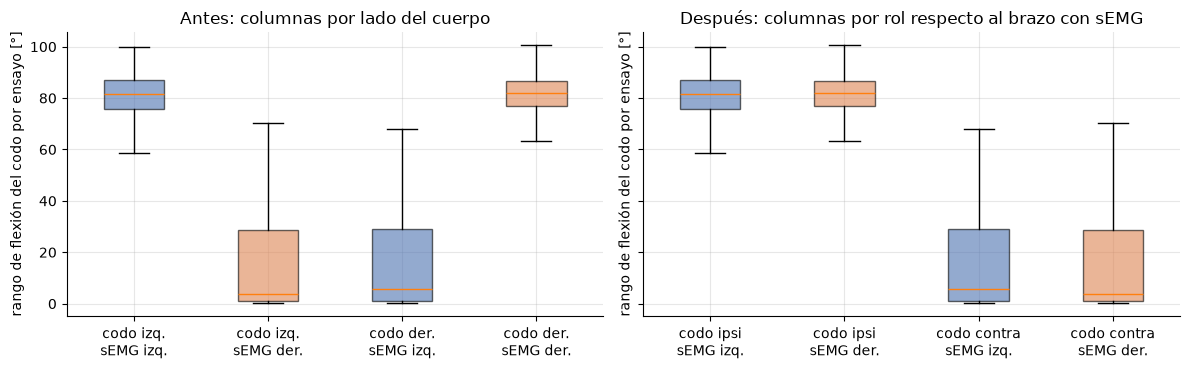

lado,codo der.,codo izq.
sEMG,,
sEMG der.,82.0,3.800000
sEMG izq.,5.8,81.599998


rol,codo contra,codo ipsi
sEMG,,
sEMG der.,3.8,82.000000
sEMG izq.,5.8,81.599998


In [6]:
rng_of = lambda v: np.percentile(v, 95) - np.percentile(v, 5)
rows_33 = []
for r in ub_tr.itertuples():
    sl = slice(r.offset, r.offset + r.n_steps)
    for s in ("Left", "Right"):
        rows_33.append({"sEMG": f"sEMG {'izq.' if r.side == 'L' else 'der.'}", "lado": f"codo {'izq.' if s == 'Left' else 'der.'}",
                        "rol": "codo ipsi" if SIDE_NAME[r.side] == s else "codo contra",
                        "rango": rng_of(R(sl, f"jointAngle__j{s}Elbow__c3"))})
rows_33 = pd.DataFrame(rows_33)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, key, order, title in ((axes[0], "lado", ["codo izq.", "codo der."], "Antes: columnas por lado del cuerpo"),
                              (axes[1], "rol", ["codo ipsi", "codo contra"], "Después: columnas por rol respecto al brazo con sEMG")):
    groups, labels, colors = [], [], []
    for g in order:
        for s, c in (("sEMG izq.", "#4c72b0"), ("sEMG der.", "#dd8452")):
            groups.append(rows_33.loc[(rows_33[key] == g) & (rows_33["sEMG"] == s), "rango"])
            labels.append(f"{g}\n{s}")
            colors.append(c)
    bp = ax.boxplot(groups, tick_labels=labels, patch_artist=True, showfliers=False)
    for patch, c in zip(bp["boxes"], colors):
        patch.set_facecolor(c); patch.set_alpha(0.6)
    ax.set(title=title, ylabel="rango de flexión del codo por ensayo [°]")
plt.tight_layout()
plt.show()
display(rows_33.pivot_table(index="sEMG", columns=["lado"], values="rango", aggfunc="median").round(1))
display(rows_33.pivot_table(index="sEMG", columns=["rol"], values="rango", aggfunc="median").round(1))

## 3.4 Escalado por modalidad

Las dos modalidades necesitan tratamientos distintos. Los escaladores se **reajustan en cada ronda** con los 10 sujetos de entrenamiento. En esta sección se muestran ajustados con los sujetos 1–10.

**sEMG: el mismo escalador del 07_LOSO.** Primero se recorta en los cuantiles 0.1 % y 99.9 %, luego se aplica `log1p` y por último (x − mediana) / IQR, por canal. La envolvente (%MVC) es muy asimétrica: casi siempre está baja y tiene picos ocasionales. El logaritmo la vuelve casi simétrica (arriba). Se conserva sin cambios para que la parte sEMG de la entrada sea igual a la del 07_LOSO.

Los parámetros no coinciden exactamente con los del avance 2 (diferencias de hasta ~13 %, impresas abajo), porque la serie sincronizada no incluye los bordes recortados de cada ensayo (sección 3.6), que son sobre todo reposo. Es el mismo procedimiento, ajustado sobre los instantes que el modelo va a usar.

**MVNX: recorte en los cuantiles 0.1 % y 99.9 %, y luego (x − mediana) / (q95 − q5).**

- **Por qué escalar:** las variables están en °, m, m/s, rad/s y 0/1. Sin escalar, los ángulos (decenas de grados) dominarían a las alturas y las rapideces (décimas de metro o de m/s) en la primera capa del encoder y en la pérdida InfoNCE (abajo, izquierda).
- **Por qué no `log1p`:** los ángulos y la velocidad vertical tienen signo.
- **Por qué el rango 5–95 % y no el IQR:** varias velocidades valen casi 0 la mayor parte del tiempo (la persona está quieta) y su IQR es casi nulo. Con el IQR, la velocidad vertical de la pelvis llegaría a valores de varios cientos, lo que desestabiliza el entrenamiento (abajo, derecha). El rango 5–95 % sigue siendo robusto a los valores atípicos, pero no se anula.
- **Contactos con el suelo:** son binarios (0/1) y ya están en una escala adecuada, así que se dejan igual.

sEMG: diferencia relativa máxima con el escalador del avance 2 (sujetos 1–10): {'lower': '6.0%', 'upper': '10.7%', 'center': '13.0%', 'scale': '9.7%'}


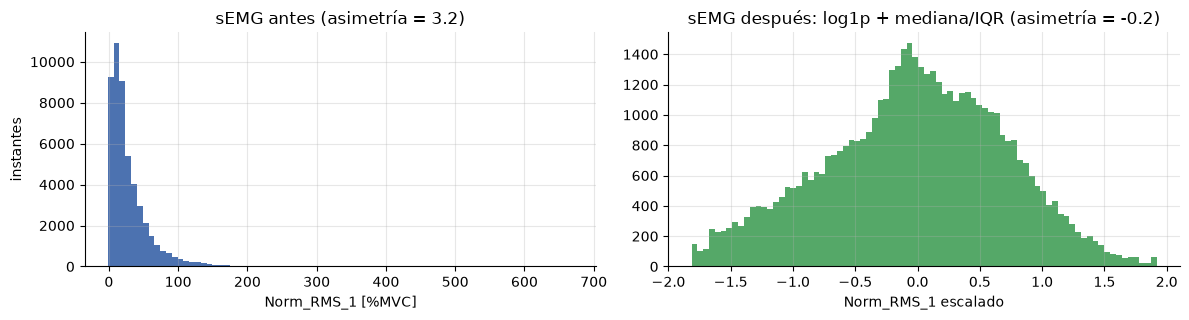

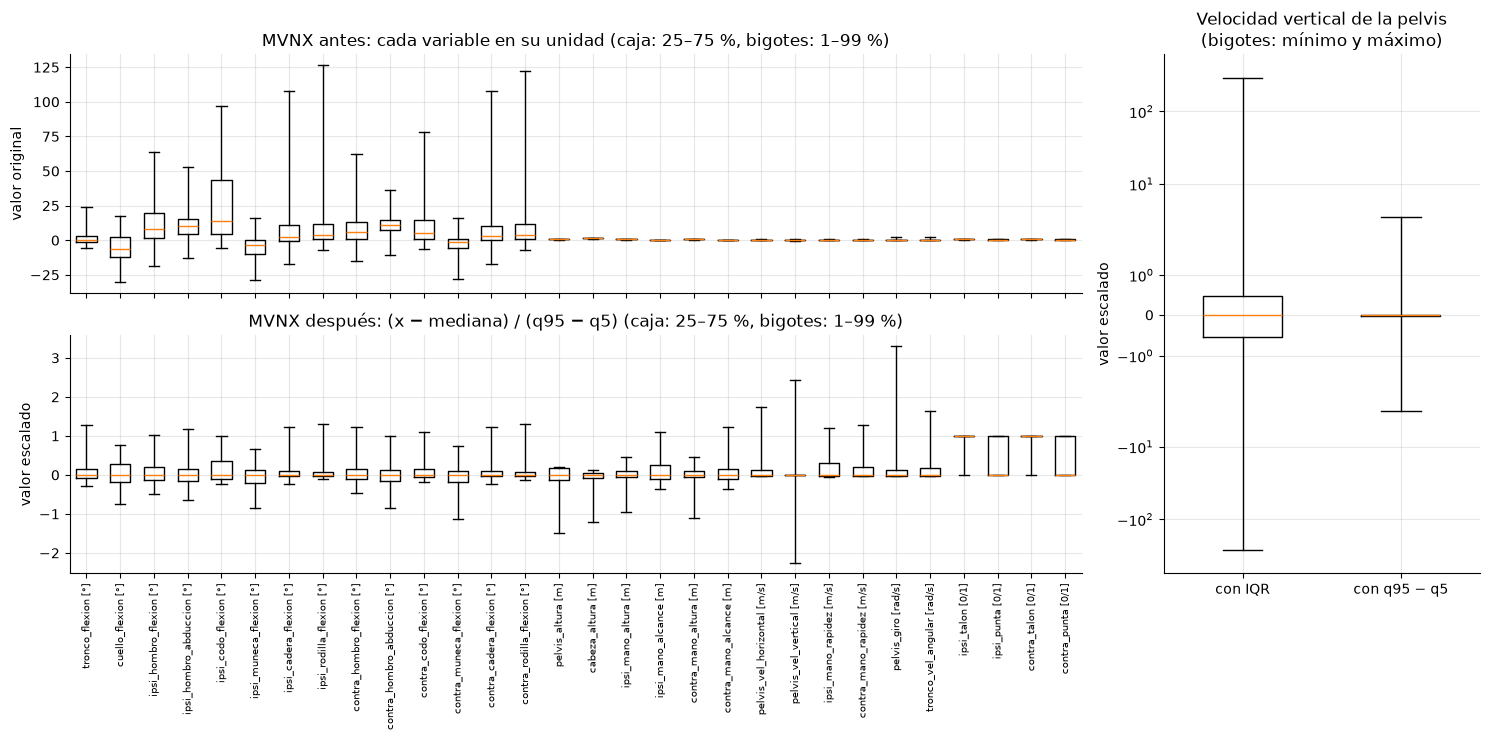

Velocidad vertical de la pelvis: IQR = 0.0037 m/s, q95 − q5 = 0.302 m/s | máximo |escalado|: con IQR 289, con q95 − q5 3.5
Todas las variables MVNX escaladas quedan en [-3.2, 4.6]


In [7]:
def fit_scaler(train_subjects, seed=SEED_DATA):
    """sEMG: clip (q0.1 %, q99.9 %) + log1p + (x − mediana) / IQR, como el 07_LOSO.
    MVNX: clip (q0.1 %, q99.9 %) + (x − mediana) / (q95 − q5). Contactos (0/1): sin cambio."""
    rows = trials[trials["subject"].isin(train_subjects)]
    idx = np.concatenate([np.arange(r.offset, r.offset + r.n_steps) for r in rows.itertuples()])
    sample = signals_raw[np.random.default_rng(seed).choice(idx, min(SCALER_FIT_POINTS, len(idx)), replace=False)].astype(np.float64)
    lower, upper = np.quantile(sample, 0.001, axis=0), np.quantile(sample, 0.999, axis=0)
    x = np.clip(sample, lower, upper)
    x[:, :N_EMG] = np.log1p(x[:, :N_EMG])
    q5, q25, center, q75, q95 = np.percentile(x, [5, 25, 50, 75, 95], axis=0)
    scale = np.concatenate([(q75 - q25)[:N_EMG], (q95 - q5)[N_EMG:]])
    scale = np.where(scale > 0, scale, 1.0)
    lower[BINARY], upper[BINARY], center[BINARY], scale[BINARY] = 0.0, 1.0, 0.0, 1.0
    return {k: v.astype(np.float32).tolist() for k, v in
            {"lower": lower, "upper": upper, "center": center, "scale": scale}.items()}


def apply_scaler(params, x=None):
    x = signals_raw if x is None else x
    lower, upper, center, scale = (np.asarray(params[k], dtype=np.float32) for k in ("lower", "upper", "center", "scale"))
    out = np.clip(x, lower, upper)
    out[:, :N_EMG] = np.log1p(out[:, :N_EMG])
    return ((out - center) / scale).astype(np.float32)


check = fit_scaler(tuple(range(1, 11)))
exported = AV2_META["preprocessing"]
gaps = {k: float(np.max(np.abs(np.asarray(check[k][:N_EMG]) - np.asarray(exported[k])) / np.maximum(np.abs(exported[k]), 1e-6)))
        for k in ("lower", "upper", "center", "scale")}
print("sEMG: diferencia relativa máxima con el escalador del avance 2 (sujetos 1–10):", {k: f"{v:.1%}" for k, v in gaps.items()})

idx_fit = np.concatenate([np.arange(r.offset, r.offset + r.n_steps) for r in trials[trials["subject"].isin(range(1, 11))].itertuples()])
plot_idx = np.random.default_rng(1).choice(idx_fit, 50_000, replace=False)
before, after = signals_raw[plot_idx], apply_scaler(check, signals_raw[plot_idx])

fig, axes = plt.subplots(1, 2, figsize=(12, 3.3))
axes[0].hist(before[:, 0], bins=80, color="#4c72b0")
axes[0].set(xlabel="Norm_RMS_1 [%MVC]", ylabel="instantes", title=f"sEMG antes (asimetría = {skew(before[:, 0]):.1f})")
axes[1].hist(after[:, 0], bins=80, color="#55a868")
axes[1].set(xlabel="Norm_RMS_1 escalado", title=f"sEMG después: log1p + mediana/IQR (asimetría = {skew(after[:, 0]):.1f})")
plt.tight_layout()
plt.show()

fig, axes = plt.subplot_mosaic([["antes", "iqr"], ["despues", "iqr"]], figsize=(15, 7.5), gridspec_kw={"width_ratios": [3.2, 1]})
units = [feature_unit(n) for n in FEATURES]
for key, values, title in (("antes", before[:, N_EMG:], "MVNX antes: cada variable en su unidad"),
                           ("despues", after[:, N_EMG:], "MVNX después: (x − mediana) / (q95 − q5)")):
    ax = axes[key]
    ax.boxplot(values, whis=(1, 99), showfliers=False, widths=0.6)
    ax.set_xticks(range(1, N_MV + 1), [f"{n} [{u}]" for n, u in zip(FEATURES, units)] if key == "despues" else [""] * N_MV,
                  rotation=90, fontsize=7)
    ax.set(title=title + " (caja: 25–75 %, bigotes: 1–99 %)")
axes["antes"].set_ylabel("valor original")
axes["despues"].set_ylabel("valor escalado")

j = CHANNELS.index("pelvis_vel_vertical")
raw_v = np.clip(before[:, j], check["lower"][j], check["upper"][j])
q5, q25, q50, q75, q95 = np.percentile(raw_v, [5, 25, 50, 75, 95])
axes["iqr"].boxplot([(raw_v - q50) / (q75 - q25), (raw_v - q50) / (q95 - q5)], whis=(0, 100), widths=0.5,
                    tick_labels=["con IQR", "con q95 − q5"])
axes["iqr"].set(yscale="symlog", title="Velocidad vertical de la pelvis\n(bigotes: mínimo y máximo)", ylabel="valor escalado")
plt.tight_layout()
plt.show()
print(f"Velocidad vertical de la pelvis: IQR = {q75 - q25:.4f} m/s, q95 − q5 = {q95 - q5:.3f} m/s | "
      f"máximo |escalado|: con IQR {np.abs((raw_v - q50) / (q75 - q25)).max():.0f}, con q95 − q5 {np.abs((raw_v - q50) / (q95 - q5)).max():.1f}")
print(f"Todas las variables MVNX escaladas quedan en [{after[:, N_EMG:].min():.1f}, {after[:, N_EMG:].max():.1f}]")

## 3.5 Ensayo bimanual → dos ensayos por brazo

Un ensayo bimanual tiene 16 canales sEMG y una sola grabación MVNX. El modelo del 07_LOSO recibe 8 canales sEMG, y su exportación ya contaba cada brazo como un ensayo. Por eso el ensayo se **parte en dos**:

- el **ensayo izquierdo** lleva los 8 canales sEMG del brazo izquierdo, su etiqueta sEMG y las variables MVNX con ipsi = izquierdo;
- el **ensayo derecho** lleva lo mismo para el brazo derecho, con ipsi = derecho.

Los dos ensayos comparten el cuerpo y el tiempo, así que el MVNX es el mismo; sólo cambia el orden de las variables ipsi/contra. Los dos quedan en el mismo sujeto, y por lo tanto siempre en la misma ronda LOSO: no puede haber fuga entre entrenamiento y evaluación.

El gráfico muestra un ensayo bimanual partido en sus dos ensayos por brazo.

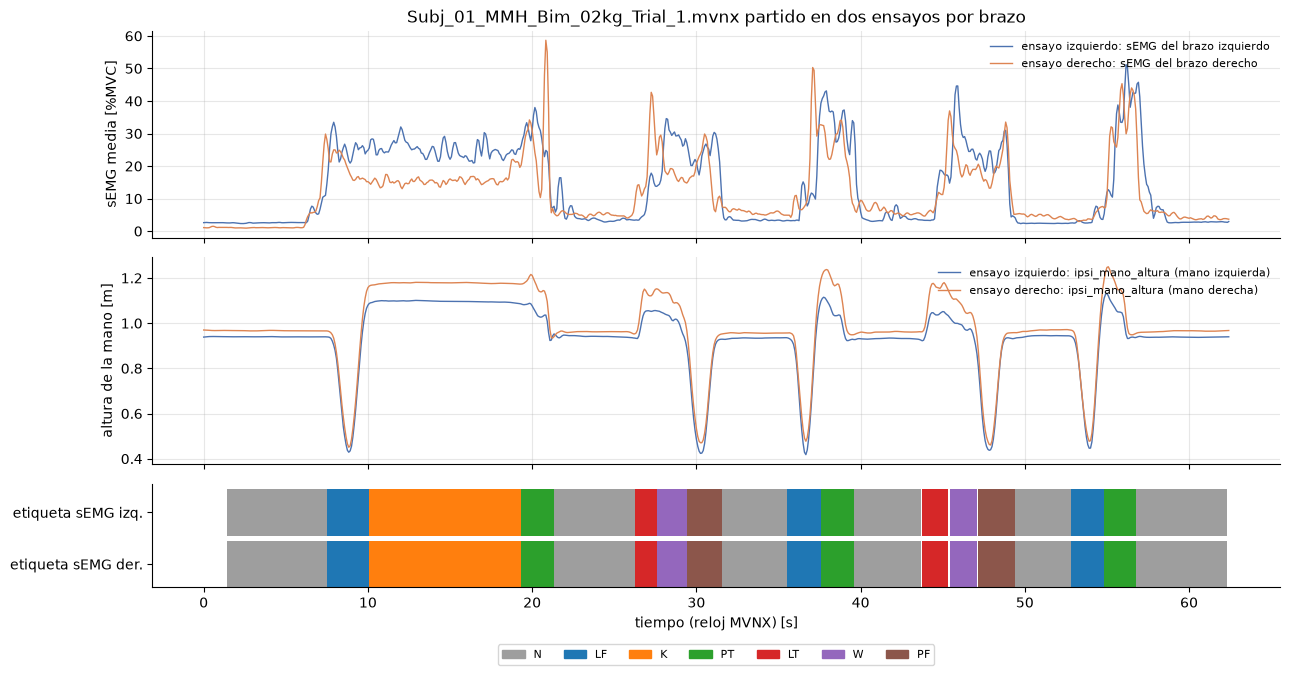

In [8]:
pair = trials[(trials["conjunto"] == "bimanual") & (trials["subject"] == 1)].head(2)
assert pair["mvnx_file"].nunique() == 1 and list(pair["side"]) == ["L", "R"]
j_hand = CHANNELS.index("ipsi_mano_altura")

fig, axes = plt.subplots(3, 1, figsize=(13, 6.8), sharex=True, gridspec_kw={"height_ratios": [2, 2, 1]})
for r, color in zip(pair.itertuples(), ("#4c72b0", "#dd8452")):
    sl = slice(r.offset, r.offset + r.n_steps)
    t = time_series[sl]
    name, hand = ("izquierdo", "izquierda") if r.side == "L" else ("derecho", "derecha")
    axes[0].plot(t, signals_raw[sl, :N_EMG].mean(axis=1), color=color, lw=1, label=f"ensayo {name}: sEMG del brazo {name}")
    axes[1].plot(t, signals_raw[sl, j_hand], color=color, lw=1, label=f"ensayo {name}: ipsi_mano_altura (mano {hand})")
    lab = labels_series[sl]
    row = 1 if r.side == "L" else 0
    for k in range(len(t) - 1):
        if lab[k] >= 0:
            axes[2].fill_between([t[k], t[k + 1]], row, row + 0.9, color=LABEL_COLORS[LABELS[lab[k]]], lw=0)
axes[0].set(ylabel="sEMG media [%MVC]", title=f"{pair.iloc[0]['mvnx_file']} partido en dos ensayos por brazo")
axes[1].set(ylabel="altura de la mano [m]")
for ax in axes[:2]:
    ax.legend(frameon=False, fontsize=8, loc="upper right")
axes[2].set(yticks=[0.45, 1.45], yticklabels=["etiqueta sEMG der.", "etiqueta sEMG izq."], xlabel="tiempo (reloj MVNX) [s]", ylim=(0, 2))
axes[2].grid(False)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in LABEL_COLORS.values()]
axes[2].legend(handles, LABEL_COLORS.keys(), ncol=7, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.5))
plt.tight_layout()
plt.show()

## 3.6 La sEMG sincronizada es la misma que vio el 07_LOSO

La línea base (sección 5) son las predicciones del 07_LOSO, que usó la serie sEMG del avance 2. La exportación sincronizada **remuestrea la sEMG sobre el reloj MVNX**, así que conviene comprobar dos cosas:

- que la señal es la misma, y sólo cambia la rejilla;
- cuánto se recorta en los bordes, porque la rejilla común empieza cuando ya hay datos de las dos fuentes y termina cuando una de ellas se acaba.

**Antes:** la serie del avance 2, en el reloj sEMG. **Después:** la serie sincronizada, en el reloj MVNX. Para superponerlas, se resta a los tiempos del avance 2 el desfase del ensayo, estimado con los eventos de las etiquetas. Si la sincronización es correcta, las curvas y las etiquetas coinciden. Las diferencias de amplitud que queden se deben sólo a la interpolación en una rejilla corrida.

El recorte se resume abajo: en total se pierde cerca de una quinta parte de la duración, pero casi todo es tiempo **sin etiqueta** antes y después de las actividades. Por eso la sección 4 conserva alrededor del 98 % de las ventanas supervisadas.

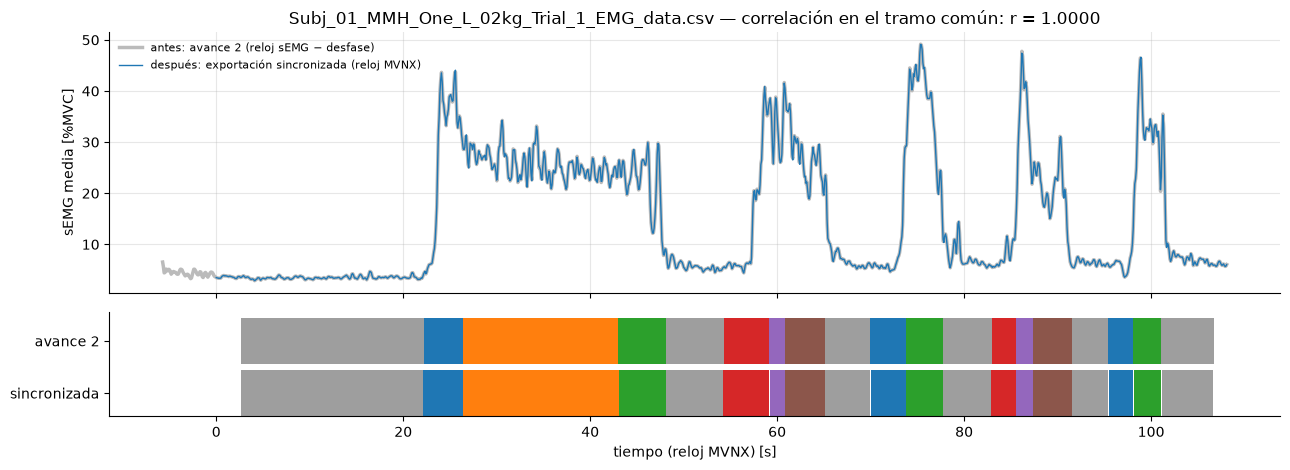

Recorte por ensayo frente al avance 2: mediana 13.7 s, p95 23.8 s | duración total conservada: 79.7%


In [9]:
with np.load(AV2_DIR / "series.npz") as z:
    av2_signals, av2_labels = z["signals"], z["labels"]
r = trials[(trials["conjunto"] == "un_brazo") & (trials["task"] == "MMH_One") & (trials["subject"] == 1)].iloc[0]
a = av2_trials.set_index("file").loc[r.file]
emg_a = av2_signals[a.offset:a.offset + a.n_steps].mean(axis=1)
lab_a = av2_labels[a.offset:a.offset + a.n_steps]
t_a = np.arange(a.n_steps) / TARGET_FS - r.desfase_s          # reloj sEMG → reloj MVNX
sl = slice(r.offset, r.offset + r.n_steps)
emg_s, lab_s, t_s = signals_raw[sl, :N_EMG].mean(axis=1), labels_series[sl], time_series[sl]
inside = (t_s >= t_a[0]) & (t_s <= t_a[-1])
r_corr = np.corrcoef(np.interp(t_s[inside], t_a, emg_a), emg_s[inside])[0, 1]

fig, axes = plt.subplots(2, 1, figsize=(13, 4.8), sharex=True, gridspec_kw={"height_ratios": [2.5, 1]})
axes[0].plot(t_a, emg_a, color="#bbbbbb", lw=2.5, label="antes: avance 2 (reloj sEMG − desfase)")
axes[0].plot(t_s, emg_s, color="#1f77b4", lw=1, label="después: exportación sincronizada (reloj MVNX)")
axes[0].set(ylabel="sEMG media [%MVC]", title=f"{r.file} — correlación en el tramo común: r = {r_corr:.4f}")
axes[0].legend(frameon=False, fontsize=8)
for row, (t, lab) in enumerate(((t_s, lab_s), (t_a, lab_a))):
    for k in range(len(t) - 1):
        if lab[k] >= 0:
            axes[1].fill_between([t[k], t[k + 1]], row, row + 0.9, color=LABEL_COLORS[LABELS[lab[k]]], lw=0)
axes[1].set(yticks=[0.45, 1.45], yticklabels=["sincronizada", "avance 2"], xlabel="tiempo (reloj MVNX) [s]", ylim=(0, 2))
axes[1].grid(False)
plt.tight_layout()
plt.show()

trim = trials[["file", "n_steps"]].merge(av2_trials[["file", "n_steps"]], on="file", suffixes=("_sync", "_av2"))
trim["recorte_s"] = (trim["n_steps_av2"] - trim["n_steps_sync"]) / TARGET_FS
print(f"Recorte por ensayo frente al avance 2: mediana {trim['recorte_s'].median():.1f} s, "
      f"p95 {trim['recorte_s'].quantile(0.95):.1f} s | duración total conservada: {trim['n_steps_sync'].sum() / trim['n_steps_av2'].sum():.1%}")

# 4. Ventanas

Se usan las mismas reglas que el avance 2 (y el 07_LOSO):

- **ventanas de 48 pasos (4 s);**
- **CPC:** una ventana cada 24 pasos, sin importar la etiqueta;
- **supervisadas:** una ventana cada 6 pasos, con la etiqueta sEMG del **instante final**; se descartan las ventanas cuyo instante final no tiene etiqueta.

La tabla compara el número de ventanas supervisadas con el del 07_LOSO. Hay un poco menos por los ensayos sin MVNX válido y los recortes de la sección 3.6.

In [10]:
def build_indices():
    sup, cpc = [], []
    for r in trials.itertuples():
        if r.n_steps < WIN:
            continue
        lab = labels_series[r.offset:r.offset + r.n_steps]
        cpc += [(r.trial_idx, r.subject, s) for s in range(0, r.n_steps - WIN + 1, CPC_HOP)]
        ends = np.arange(WIN - 1, r.n_steps, SUP_HOP)
        sup += [(r.trial_idx, r.subject, e - WIN + 1, e, lab[e]) for e in ends[lab[ends] >= 0]]
    return (pd.DataFrame(sup, columns=["trial_idx", "subject", "start_step", "end_step", "target"]),
            pd.DataFrame(cpc, columns=["trial_idx", "subject", "start_step"]))


sup_index, cpc_index = build_indices()
sup_cv = sup_index[sup_index["subject"].isin(CV_SUBJECTS)]
cpc_cv = cpc_index[cpc_index["subject"].isin(CV_SUBJECTS)]
assert not sup_cv["subject"].isin(TEST_SUBJECTS).any() and not cpc_cv["subject"].isin(TEST_SUBJECTS).any()

av2_sup = pd.read_csv(AV2_DIR / "supervised_index.csv.gz")
av2_sup_cv = av2_sup[av2_sup["subject"].isin(CV_SUBJECTS)]
compare = pd.DataFrame({"07_LOSO (avance 2)": av2_sup_cv.groupby("subject").size(), "sincronizadas": sup_cv.groupby("subject").size()})
compare["conservadas"] = (compare["sincronizadas"] / compare["07_LOSO (avance 2)"]).map("{:.0%}".format)
print(f"Ventanas supervisadas (sujetos 1–12): {len(sup_cv):,} | ventanas CPC: {len(cpc_cv):,}")
display(compare.T)
display(pd.DataFrame({"07_LOSO (avance 2)": av2_sup_cv["target"].value_counts(normalize=True).sort_index(),
                      "sincronizadas": sup_cv["target"].value_counts(normalize=True).sort_index()})
        .rename(index=dict(enumerate(LABELS))).T.round(3))

S_T = None
WIN_RANGE = torch.arange(WIN, device=DEVICE)

def set_series(scaled):
    """Sube al dispositivo la serie escalada de la ronda actual."""
    global S_T
    S_T = torch.from_numpy(np.ascontiguousarray(scaled.T)).to(DEVICE)

def starts_of(frame):
    return offsets[frame["trial_idx"].to_numpy()] + frame["start_step"].to_numpy()

def get_windows(starts):
    idx = torch.as_tensor(np.asarray(starts), device=DEVICE)[:, None] + WIN_RANGE
    return S_T[:, idx].permute(1, 0, 2)

Ventanas supervisadas (sujetos 1–12): 51,814 | ventanas CPC: 14,500


subject,1,2,3,4,5,6,7,8,9,10,11,12
07_LOSO (avance 2),5076,3633,4294,4023,4402,3959,4602,4719,4508,4017,5954,4036
sincronizadas,4958,3558,4212,4009,4398,3823,4043,4635,4407,3918,5864,3989
conservadas,98%,98%,98%,100%,100%,97%,88%,98%,98%,98%,98%,99%


target,N,LF,K,PT,LT,W,PF
07_LOSO (avance 2),0.429,0.097,0.087,0.146,0.090,0.08,0.071
sincronizadas,0.425,0.097,0.088,0.148,0.091,0.08,0.072


# 5. Línea base: sEMG sola, en los mismos ensayos

No hace falta reentrenar el modelo de sEMG. El 07_LOSO guardó la predicción de cada ventana del sujeto evaluado (`ronda_*.json`), en el mismo orden que su índice de ventanas supervisadas, porque no hubo submuestreo (`EVAL_CAP = None`). Se hace lo siguiente:

1. se comprueba que las etiquetas guardadas coinciden ventana por ventana con ese índice;
2. se recalcula el F1 de cada ronda con todas las ventanas, que debe reproducir el 07_LOSO;
3. se recalcula el F1 **sólo con las ventanas de los ensayos que también están en la exportación sincronizada**.

El paso 3 es la línea base de este notebook. **Limitación:** son los mismos ensayos, pero no exactamente las mismas ventanas. Las ventanas sincronizadas están corridas unos milisegundos y no incluyen los bordes recortados (sección 3.6). Para una prueba es aceptable; una diferencia pequeña (menos de unos 0.02) habría que confirmarla re-ejecutando la sEMG sola en la rejilla sincronizada.

In [11]:
base_rows = []
for p in sorted(LOSO_DIR.glob("ronda_*.json")):
    r = json.loads(p.read_text())
    w = av2_sup_cv[av2_sup_cv["subject"] == r["held_out"]]
    y, pred = np.asarray(r["y"]), np.asarray(r["pred"][METHOD])
    assert len(w) == len(y) and (w["target"].to_numpy() == y).all(), f"El orden de {p.name} no coincide con el índice"
    f1_all = f1_score(y, pred, average="macro")
    assert abs(f1_all - r["metrics"][METHOD]["f1_macro"]) < 1e-9
    keep = w["file"].isin(trials["file"]).to_numpy()
    base_rows.append({"sujeto": r["held_out"], "semilla": r["seed"], "F1 todas las ventanas": f1_all,
                      "F1 ensayos sincronizados": f1_score(y[keep], pred[keep], average="macro"),
                      "ventanas conservadas": keep.mean(), "y": y[keep], "pred": pred[keep],
                      "file": w["file"].to_numpy()[keep]})
baseline = pd.DataFrame(base_rows)

def baseline_f1(subject, seed):
    return float(baseline.loc[(baseline["sujeto"] == subject) & (baseline["semilla"] == seed), "F1 ensayos sincronizados"].iloc[0])

view = baseline.pivot(index="sujeto", columns="semilla", values=["F1 todas las ventanas", "F1 ensayos sincronizados"])
view.loc["media"] = view.mean()
print(f"07_LOSO, {METHOD}: el F1 con todas las ventanas reproduce el notebook 07; la línea base es el F1 en los ensayos sincronizados.")
display(view.round(3))

07_LOSO, ajuste fino preentrenado: el F1 con todas las ventanas reproduce el notebook 07; la línea base es el F1 en los ensayos sincronizados.


F1 todas las ventanas        F1 ensayos sincronizados       
semilla                     0      1                        0      1
sujeto                                                              
1                       0.424  0.431                    0.424  0.431
2                       0.337  0.393                    0.337  0.393
3                       0.547  0.520                    0.547  0.520
4                       0.422  0.425                    0.422  0.425
5                       0.429  0.419                    0.429  0.419
6                       0.397  0.342                    0.399  0.341
7                       0.333  0.342                    0.334  0.346
8                       0.473  0.474                    0.473  0.474
9                       0.469  0.445                    0.468  0.444
10                      0.397  0.412                    0.397  0.412
11                      0.511  0.607                    0.511  0.607
12                      0.454  0.483                    0.454  0.483
media                   0.433  0.441                    0.433  0.441

# 6. Modelo

Las clases son **exactamente** las del 07_LOSO (que a su vez son las del notebook 06): encoder causal, `g_ar` sLSTM, predictor de horizontes, InfoNCE y `CPCModel`. Sólo cambia `n_channels`, que se toma de la serie (8 + 30 = 38). Se omiten las clases de mLSTM, que no se usan.

In [12]:
@dataclass
class CPCConfig:
    """
    Hiperparámetros de CPC (los mismos del notebook 01), más `pred_horizons`:
    la lista de horizontes k que se predicen. Vacía = k = 1..n_pred_steps, el comportamiento original.
    """
    # --- entrada ---
    n_channels: int = 6

    # --- g_enc: encoder convolucional ---
    enc_channels: tuple = (32, 64, 128)
    enc_kernel_size: int = 3
    enc_dropout: float = 0.2

    # --- g_ar: modelo autorregresivo ---
    ar_hidden_size: int = 256
    ar_num_layers: int = 2
    ar_dropout: float = 0.2

    # --- predicción / pérdida contrastiva ---
    n_pred_steps: int = 12                  # K: número de horizontes
    n_anchors: int = 4                      # nº de instantes de anclaje por batch de entrenamiento
    pred_horizons: tuple = ()               # NUEVO: horizontes k (en pasos); vacío = 1..n_pred_steps

    @property
    def horizons(self) -> tuple:
        return tuple(self.pred_horizons) or tuple(range(1, self.n_pred_steps + 1))

    @property
    def z_dim(self) -> int:
        return self.enc_channels[-1]

    @property
    def c_dim(self) -> int:
        return self.ar_hidden_size

In [13]:
class CausalEncoder(nn.Module):
    """g_enc causal: bloques Conv1d -> ReLU -> Dropout sin stride (Haresamudram et al., 2020),
    con relleno sólo a la izquierda: z_t depende de x_{t-3..t}, nunca del futuro.

        x: (B, n_channels, T)  -->  z: (B, z_dim, T)
    """

    def __init__(self, cfg: CPCConfig):
        super().__init__()
        k = cfg.enc_kernel_size
        self.left_pad = k - 1
        in_channels = (cfg.n_channels,) + cfg.enc_channels[:-1]
        self.convs = nn.ModuleList([nn.Conv1d(c_in, c_out, kernel_size=k) for c_in, c_out in zip(in_channels, cfg.enc_channels)])
        self.dropout = nn.Dropout(cfg.enc_dropout)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        z = x
        for conv in self.convs:
            z = self.dropout(F.relu(conv(F.pad(z, (self.left_pad, 0)))))
        return z

In [14]:
class AutoRegressive(nn.Module):
    """
    g_ar: modelo autorregresivo genérico (GRU multicapa).

        z: (B, L, z_dim)  -->  c: (B, L, c_dim)

    Los parámetros de GRU se especifican en la clase cfg. De acuerdo al paper: 
    - input_size: 128
    - hidden_Size: 256
    - num_layer: 2

    c[:, t] resume z[:, :t+1] de forma causal (una GRU nunca mira el futuro),
    que es la propiedad necesaria para usar c_t como predictor de z_{t+k}.

    Arquitectura (Haresamudram, Essa & Plötz, 2020): GRU de 2 capas con 256
    unidades ocultas y dropout entre capas.
    """

    def __init__(self, cfg: CPCConfig):
        super().__init__()
        self.gru = nn.GRU(
            input_size=cfg.z_dim,
            hidden_size=cfg.ar_hidden_size,
            num_layers=cfg.ar_num_layers,
            dropout=cfg.ar_dropout if cfg.ar_num_layers > 1 else 0.0,  # PyTorch exige 0 si num_layers==1
            batch_first=True,
        )

    def forward(self, z: torch.Tensor) -> torch.Tensor:
        c, _ = self.gru(z)        # c: (B, L, c_dim) - Hace un loop sobre todo el eje temporal toma el c_{t-1} e incorpora el nuevo paso z_t
        return c

In [15]:
class Predictor(nn.Module):
    """
    Cabezas de predicción log-bilineal: una W_k (sin sesgo) por cada horizonte de cfg.horizons.

        c_t: (B, c_dim) -> (n_horizontes, B, z_dim),  con pred_k = W_k c_t ≈ z_{t+k}
    """

    def __init__(self, cfg: CPCConfig):
        super().__init__()
        self.horizons = cfg.horizons
        self.heads = nn.ModuleList([nn.Linear(cfg.c_dim, cfg.z_dim, bias=False) for _ in self.horizons])

    def forward(self, c_t: torch.Tensor) -> torch.Tensor:
        return torch.stack([head(c_t) for head in self.heads], dim=0)


class InfoNCE(nn.Module):
    """
    Pérdida contrastiva de CPC (Ec. 4) con negativos de minibatch, para cada horizonte de la lista.
    Para el horizonte k, el positivo de la secuencia i es z_{t+k}^(i) y los negativos son los
    z_{t+k}^(j) (j != i) de las otras secuencias del batch.
    """

    def __init__(self, horizons: tuple):
        super().__init__()
        self.horizons = tuple(horizons)

    def forward(self, preds: torch.Tensor, z: torch.Tensor, t: int):
        """
        preds: (n_horizontes, B, z_dim) · z: (B, L, z_dim) · t: instante de anclaje
        Devuelve (loss_mean, loss_per_k, acc_per_k), los dos últimos de forma (n_horizontes,).
        """
        H, B, _ = preds.shape
        target = torch.arange(B, device=preds.device)
        loss_per_k = torch.zeros(H, device=preds.device)
        acc_per_k = torch.zeros(H, device=preds.device)
        for j, k in enumerate(self.horizons):
            logits = preds[j] @ z[:, t + k, :].t()          # (B, B): S_ij = pred_i · z_{t+k}^(j)
            loss_per_k[j] = F.cross_entropy(logits, target)
            acc_per_k[j] = (logits.argmax(dim=1) == target).float().mean()
        return loss_per_k.mean(), loss_per_k, acc_per_k.detach()


class CPCModel(nn.Module):
    """Modelo CPC completo (Encoder + g_ar + Predictor + InfoNCE), con horizontes de cfg.horizons."""

    def __init__(self, cfg: CPCConfig):
        super().__init__()
        self.cfg = cfg
        self.encoder = CausalEncoder(cfg)          # encoder causal (sección 3.1)
        self.ar = AutoRegressive(cfg)
        self.predictor = Predictor(cfg)
        self.info_nce_loss = InfoNCE(cfg.horizons)

    def encode(self, x: torch.Tensor):
        """x: (B, n_channels, T) -> z: (B, T, z_dim), c: (B, T, c_dim)"""
        z = self.encoder(x).transpose(1, 2)
        return z, self.ar(z)

    def anchor_range(self, L: int):
        lo, hi = max(1, L // 8), L - max(self.cfg.horizons)   # deja sitio para leer z_{t+k_máx}
        if hi <= lo:
            raise ValueError(f"Ventana T={L} demasiado corta para el horizonte {max(self.cfg.horizons)}")
        return lo, hi

    def info_nce(self, x: torch.Tensor, anchors=None):
        z, c = self.encode(x)
        if anchors is None:
            anchors = torch.randint(*self.anchor_range(z.shape[1]), size=(self.cfg.n_anchors,)).tolist()
        losses, accs = [], []
        for t in anchors:
            _, loss_per_k, acc_per_k = self.info_nce_loss(self.predictor(c[:, t, :]), z, t)
            losses.append(loss_per_k)
            accs.append(acc_per_k)
        loss_per_k = torch.stack(losses).mean(dim=0)
        acc_per_k = torch.stack(accs).mean(dim=0)
        return loss_per_k.mean(), loss_per_k, acc_per_k

In [16]:
class BlockDiagonalLinear(nn.Module):
    """
    Capa lineal con matriz de pesos block-diagonal: cada "head" (bloque) solo mezcla sus propias
    dimensiones. Es la forma en que xLSTM limita la mezcla entre celdas (sLSTM) o abarata las
    proyecciones q, k, v (mLSTM).

        x: (..., dim) -> (..., dim)     con n_blocks bloques de tamaño dim // n_blocks
    """

    def __init__(self, dim: int, n_blocks: int, bias: bool = True):
        super().__init__()
        assert dim % n_blocks == 0, "dim debe ser múltiplo de n_blocks"
        self.n_blocks, self.block = n_blocks, dim // n_blocks
        self.weight = nn.Parameter(torch.randn(n_blocks, self.block, self.block) / math.sqrt(self.block))
        self.bias = nn.Parameter(torch.zeros(dim)) if bias else None

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        shape = x.shape
        x = x.reshape(*shape[:-1], self.n_blocks, self.block)
        y = torch.einsum("...nd,ned->...ne", x, self.weight).reshape(shape)
        return y if self.bias is None else y + self.bias

In [17]:
class sLSTMCell(nn.Module):
    """
    Celda sLSTM (Beck et al. 2024, Ec. 34-40, con estabilización Ec. 15-17).

        x: (B, T, dim) -> h: (B, T, dim)

    Diferencias con la LSTM clásica:
      - compuerta de entrada EXPONENCIAL  i_t = exp(ĩ_t)  (permite "revisar" decisiones de memoria)
      - estado normalizador  n_t = f_t n_{t-1} + i_t,  y  h_t = o_t * c_t / n_t
      - estado estabilizador m_t para que exp() no desborde (no cambia el resultado)
      - memory mixing por heads: la recurrencia R h_{t-1} es block-diagonal (n_heads bloques)

    Es recurrente (no paralelizable): recorre el tiempo paso a paso, igual que la GRU.
    """

    def __init__(self, dim: int, n_heads: int):
        super().__init__()
        self.dim = dim
        self.W = nn.Linear(dim, 4 * dim)                                     # entrada -> z, i, f, o
        self.R = nn.ModuleList([BlockDiagonalLinear(dim, n_heads, bias=False) for _ in range(4)])
        with torch.no_grad():                                                # sesgo de la forget gate en [3, 6]
            self.W.bias[2 * dim:3 * dim] = torch.linspace(3.0, 6.0, dim)    # (Tabla 2 del paper): al inicio "recuerda"

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        B, T, D = x.shape
        Wx = self.W(x)                                                       # parte de la entrada, para todo t a la vez
        h = c = n = m = x.new_zeros(B, D)
        outputs = []
        for t in range(T):
            Rh = torch.cat([r(h) for r in self.R], dim=-1)                   # parte recurrente (memory mixing)
            z_pre, i_pre, f_pre, o_pre = (Wx[:, t] + Rh).chunk(4, dim=-1)
            log_f = F.logsigmoid(f_pre)                                      # forget gate sigmoide, en log
            m_new = torch.maximum(log_f + m, i_pre)                          # Ec. 15: estabilizador
            i_gate = torch.exp(i_pre - m_new)                                # Ec. 16: i' (exponencial estabilizada)
            f_gate = torch.exp(log_f + m - m_new)                            # Ec. 17: f'
            c = f_gate * c + i_gate * torch.tanh(z_pre)                      # Ec. 34: estado de celda
            n = f_gate * n + i_gate                                          # Ec. 35: normalizador
            h = torch.sigmoid(o_pre) * c / n                                 # Ec. 36: estado oculto
            m = m_new
            outputs.append(h)
        return torch.stack(outputs, dim=1)

In [18]:
class sLSTMBlock(nn.Module):
    """
    Bloque residual sLSTM con "post up-projection" (Fig. 10 del paper, sin la convolución opcional):

        x -> LayerNorm -> sLSTM (n_heads) -> GroupNorm -> (+x)
          -> LayerNorm -> MLP con compuerta (factor 4/3, GeLU) -> (+x)
    """

    def __init__(self, dim: int, n_heads: int, dropout: float, proj_factor: float = 4 / 3):
        super().__init__()
        inner = int(round(proj_factor * dim))
        self.ln1, self.ln2 = nn.LayerNorm(dim), nn.LayerNorm(dim)
        self.cell = sLSTMCell(dim, n_heads)
        self.gn = nn.GroupNorm(n_heads, dim)                                 # LayerNorm por head
        self.up_a, self.up_b = nn.Linear(dim, inner), nn.Linear(dim, inner)
        self.down = nn.Linear(inner, dim)
        self.drop = nn.Dropout(dropout)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        h = self.cell(self.ln1(x))
        h = self.gn(h.reshape(-1, h.shape[-1])).reshape(h.shape)
        x = x + self.drop(h)
        y = self.ln2(x)
        return x + self.drop(self.down(self.up_a(y) * F.gelu(self.up_b(y))))

In [19]:
class xLSTMAutoRegressive(nn.Module):
    """
    g_ar alternativo a la GRU, con la MISMA interfaz que AutoRegressive del notebook 01:

        z: (B, T, z_dim) -> c: (B, T, c_dim)

    Proyecta z_t a c_dim y apila `n_blocks` bloques xLSTM residuales (todos sLSTM o todos mLSTM),
    como la GRU apila 2 capas. Todo es causal: c_t solo depende de z_1..z_t.
    """

    def __init__(self, cfg: CPCConfig, kind: str, n_blocks: int = 2, n_heads: int = 4):
        super().__init__()
        assert kind == "sLSTM", "este notebook sólo usa la sLSTM"
        Block = sLSTMBlock
        self.proj = nn.Linear(cfg.z_dim, cfg.c_dim)
        self.blocks = nn.ModuleList([Block(cfg.c_dim, n_heads, cfg.ar_dropout) for _ in range(n_blocks)])
        self.ln_out = nn.LayerNorm(cfg.c_dim)

    def forward(self, z: torch.Tensor) -> torch.Tensor:
        x = self.proj(z)
        for block in self.blocks:
            x = block(x)
        return self.ln_out(x)

In [20]:
def build_model(kind: str, horizons: tuple, seed: int, device=None) -> CPCModel:
    """CPC completo con el g_ar elegido. La semilla fija los pesos iniciales (misma semilla = misma red)."""
    cfg = CPCConfig(n_channels=N_CH, n_pred_steps=len(horizons), n_anchors=4, pred_horizons=tuple(horizons))
    torch.manual_seed(seed)
    model = CPCModel(cfg)
    if kind != "GRU":
        model.ar = xLSTMAutoRegressive(cfg, kind)
    return model.to(device or DEVICE)


def summarize(c: torch.Tensor, representation: str) -> torch.Tensor:
    """c: (B, T, c_dim) -> vector por ventana."""
    if representation == "c_T":
        return c[:, -1]
    if representation == "cola":
        return c[:, -TAIL:].mean(dim=1)
    if representation == "media":
        return c.mean(dim=1)
    if representation == "c_T+media":
        return torch.cat([c[:, -1], c.mean(dim=1)], dim=1)
    raise ValueError(representation)

# 7. Verificaciones y estimación de tiempo

1. **Causalidad** del modelo completo desde la entrada, ahora con 38 canales: perturbar la señal a partir de `T/2` no debe cambiar nada antes de `T/2`.
2. **Tiempo:** se miden pasos de preentrenamiento y de ajuste fino. Cada ronda tiene un solo ajuste fino, en lugar de los dos ajustes y las tres sondas del 07_LOSO.

In [21]:
def sync():
    if DEVICE.type == "mps":
        torch.mps.synchronize()
    elif DEVICE.type == "cuda":
        torch.cuda.synchronize()

set_series(apply_scaler(check))
model = build_model(KIND, HORIZONS, seed=0).eval()
assert model.cfg.n_channels == N_CH == N_EMG + N_MV
x = torch.randn(4, N_CH, WIN, device=DEVICE)
x_mod = x.clone()
x_mod[:, :, WIN // 2:] += torch.randn_like(x_mod[:, :, WIN // 2:])
with torch.no_grad():
    past = (model.encode(x)[1][:, :WIN // 2] - model.encode(x_mod)[1][:, :WIN // 2]).abs().max().item()
assert past == 0.0, f"Fuga temporal: {past:.2e}"
print("Causalidad desde la entrada: OK")

starts_pool = starts_of(cpc_cv)
model.train()
opt = torch.optim.Adam(model.parameters(), lr=LR)
for it in range(5):
    if it == 2:
        sync(); t0 = time.time()
    loss, _, _ = model.info_nce(get_windows(np.random.default_rng(it).choice(starts_pool, BATCH_SIZE)))
    opt.zero_grad(); loss.backward(); opt.step()
sync()
cpc_step = (time.time() - t0) / 3

head = nn.Linear(model.cfg.c_dim, len(LABELS)).to(DEVICE)
sup_pool = starts_of(sup_cv)
for it in range(5):
    if it == 2:
        sync(); t0 = time.time()
    xb = get_windows(np.random.default_rng(it).choice(sup_pool, FINETUNE_BATCH))
    loss = F.cross_entropy(head(model.encode(xb)[1][:, -1]), torch.zeros(FINETUNE_BATCH, dtype=torch.long, device=DEVICE))
    opt.zero_grad(); loss.backward(); opt.step()
sync()
ft_step = (time.time() - t0) / 3
del model, head, opt

n_steps_cpc = len(cpc_cv) * 10 // 12 // BATCH_SIZE
n_steps_ft = len(sup_cv) * 10 // 12 // FINETUNE_BATCH
# Épocas típicas en el notebook 06: ~12 de CPC y ~9 de ajuste fino; + evaluaciones (~3 min).
fold_min = (cpc_step * n_steps_cpc * 12 + ft_step * n_steps_ft * 9) / 60 + 3
total_h = fold_min * len(FOLDS) * len(SEEDS) / 60
print(f"Paso CPC: {cpc_step:.2f} s · paso de ajuste fino: {ft_step:.2f} s")
print(f"Estimación: ≈ {fold_min:.0f} min por ronda · {len(FOLDS)} rondas × {len(SEEDS)} semillas ≈ {total_h:.1f} h")
print(f"Término aproximado si se ejecuta ahora: {(datetime.now() + timedelta(hours=total_h)):%d/%m %H:%M}")

Causalidad desde la entrada: OK


Paso CPC: 0.20 s · paso de ajuste fino: 0.34 s
Estimación: ≈ 15 min por ronda · 12 rondas × 1 semillas ≈ 3.1 h
Término aproximado si se ejecuta ahora: 21/10 21:24


# 8. Herramientas de entrenamiento y evaluación

Las mismas funciones del 07_LOSO: `make_sets`, `CPCBatchSampler`, `train_cpc` (preentrenamiento con parada temprana por la sonda lineal en el sujeto de validación interna), `finetune` y `predict`.

**`run_fold`** se simplifica: preentrena CPC, hace **un** ajuste fino, evalúa al sujeto que quedó fuera y guarda el índice, la etiqueta y la predicción de cada ventana (`.json`) y los pesos (`.pt`). Cada línea de `progreso.log` muestra el F1 de sEMG + MVNX junto al de la sEMG sola en la misma ronda.

In [22]:
def eval_set(frame, cap=None):
    if cap is not None and len(frame) > cap:
        frame = frame.groupby("target", group_keys=False).sample(frac=cap / len(frame), random_state=SEED_DATA)
    return {"index": frame.index.to_numpy(), "starts": starts_of(frame), "y": frame["target"].to_numpy()}


def make_sets(train_subjects, inner_val, held_out):
    train = sup_cv[sup_cv["subject"].isin(train_subjects)]
    return {
        "probe_train": eval_set(train, PROBE_TRAIN_MAX),
        "ft_train": eval_set(train, FT_TRAIN_CAP),
        "val": eval_set(sup_cv[sup_cv["subject"] == inner_val], EVAL_CAP),
        "held": eval_set(sup_cv[sup_cv["subject"] == held_out], EVAL_CAP),
        "val_cpc_starts": starts_of(cpc_cv[cpc_cv["subject"] == inner_val]),
        "n_steps": max(1, len(cpc_cv[cpc_cv["subject"].isin(train_subjects)]) // BATCH_SIZE),
    }


class CPCBatchSampler:
    """Inicios de ventana al azar en los ensayos de los sujetos dados; con `mismo_sujeto`, un sujeto por batch."""

    def __init__(self, subjects, batch_mode, seed):
        self.rng, self.batch_mode = np.random.default_rng(seed), batch_mode
        rows = [r for r in trials[trials["subject"].isin(subjects)].itertuples() if r.n_steps >= WIN]
        self.starts = np.concatenate([np.arange(r.offset, r.offset + r.n_steps - WIN + 1) for r in rows])
        subj = np.concatenate([np.full(r.n_steps - WIN + 1, r.subject) for r in rows])
        self.by_subject = {s: self.starts[subj == s] for s in np.unique(subj)}
        sizes = np.array([len(v) for v in self.by_subject.values()], dtype=float)
        self.p = sizes / sizes.sum()

    def batch(self):
        if self.batch_mode == "mezclado":
            return self.rng.choice(self.starts, BATCH_SIZE, replace=False)
        pool = self.by_subject[self.rng.choice(list(self.by_subject), p=self.p)]
        return self.rng.choice(pool, BATCH_SIZE, replace=len(pool) < BATCH_SIZE)


def metrics(y_true, y_pred):
    ids = list(range(len(LABELS)))
    return {"f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
            "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
            "f1_per_class": f1_score(y_true, y_pred, labels=ids, average=None, zero_division=0).tolist()}


def summarize(c, representation=REP):
    if representation == "c_T":
        return c[:, -1]
    if representation == "cola":
        return c[:, -TAIL:].mean(dim=1)
    if representation == "media":
        return c.mean(dim=1)
    return torch.cat([c[:, -1], c.mean(dim=1)], dim=1)


@torch.no_grad()
def extract(model, starts, batch=512):
    model.eval()
    return np.concatenate([summarize(model.encode(get_windows(starts[s:s + batch]))[1]).float().cpu().numpy()
                           for s in range(0, len(starts), batch)])


def fit_probe(X, y):
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")).fit(X, y)


def probe_predictions(model, sets, targets=("held",)):
    clf = fit_probe(extract(model, sets["probe_train"]["starts"]), sets["probe_train"]["y"])
    return {k: clf.predict(extract(model, sets[k]["starts"])) for k in targets}


@torch.no_grad()
def contrastive_eval(model, starts_pool, n_batches=20):
    model.eval()
    g = np.random.default_rng(SEED_DATA)
    lo, hi = model.anchor_range(WIN)
    losses = []
    for _ in range(min(n_batches, len(starts_pool) // BATCH_SIZE)):
        anchors = g.integers(lo, hi, size=model.cfg.n_anchors).tolist()
        losses.append(model.info_nce(get_windows(g.choice(starts_pool, BATCH_SIZE, replace=False)), anchors=anchors)[0].item())
    return float(np.mean(losses)) if losses else float("nan")


def train_cpc(train_subjects, sets, seed):
    model = build_model(KIND, HORIZONS, seed)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    sampler = CPCBatchSampler(train_subjects, BATCH_MODE, seed)
    n_steps = min(sets["n_steps"], STEPS_CAP) if STEPS_CAP else sets["n_steps"]
    torch.manual_seed(seed)
    best, bad, history, t0 = {"f1": -1.0, "epoch": 0, "state": copy.deepcopy(model.state_dict())}, 0, [], time.time()
    for epoch in range(1, EPOCHS_MAX + 1):
        model.train()
        run_loss = 0.0
        for _ in range(n_steps):
            loss, _, _ = model.info_nce(get_windows(sampler.batch()))
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            opt.step()
            run_loss += loss.item()
        row = {"epoch": epoch, "train_loss": run_loss / n_steps, "val_loss": contrastive_eval(model, sets["val_cpc_starts"])}
        if epoch % EVAL_EVERY == 0 or epoch == EPOCHS_MAX:
            row["f1_val"] = f1_score(sets["val"]["y"], probe_predictions(model, sets, ("val",))["val"], average="macro")
            if row["f1_val"] > best["f1"] + 1e-4:
                best, bad = {"f1": row["f1_val"], "epoch": epoch, "state": copy.deepcopy(model.state_dict())}, 0
            else:
                bad += 1
        history.append(row)
        if bad >= PATIENCE:
            break
    model.load_state_dict(best["state"])
    return model, {"best_epoch": best["epoch"], "f1_val": best["f1"], "history": history, "minutes": (time.time() - t0) / 60}


class CPCClassifier(nn.Module):
    def __init__(self, cpc_model, representation=REP, n_classes=len(LABELS)):
        super().__init__()
        self.encoder, self.ar, self.representation = cpc_model.encoder, cpc_model.ar, representation
        dim = cpc_model.cfg.c_dim * (2 if representation == "c_T+media" else 1)
        self.head = nn.Sequential(nn.LayerNorm(dim), nn.Dropout(0.2), nn.Linear(dim, n_classes))

    def forward(self, x):
        return self.head(summarize(self.ar(self.encoder(x).transpose(1, 2)), self.representation))


@torch.no_grad()
def predict(model, starts, batch=512):
    model.eval()
    return np.concatenate([model(get_windows(starts[s:s + batch])).argmax(1).cpu().numpy()
                           for s in range(0, len(starts), batch)])


def finetune(base, sets, seed):
    torch.manual_seed(seed)
    model = CPCClassifier(base).to(DEVICE)
    opt = torch.optim.AdamW([
        {"params": list(model.encoder.parameters()) + list(model.ar.parameters()), "lr": FINETUNE_LR_BACKBONE},
        {"params": model.head.parameters(), "lr": FINETUNE_LR_HEAD}], weight_decay=1e-4)
    train = sets["ft_train"]
    counts = np.bincount(train["y"], minlength=len(LABELS))
    weights = torch.tensor(counts.sum() / (len(LABELS) * np.maximum(counts, 1)), dtype=torch.float32, device=DEVICE)
    y_all = torch.as_tensor(np.array(train["y"]), device=DEVICE)
    rng = np.random.default_rng(seed)
    best, bad, history, t0 = {"f1": -1.0, "epoch": 0, "state": None}, 0, [], time.time()
    for epoch in range(1, FINETUNE_EPOCHS + 1):
        model.train()
        order = rng.permutation(len(train["y"]))
        for s in range(0, len(order), FINETUNE_BATCH):
            idx = order[s:s + FINETUNE_BATCH]
            loss = F.cross_entropy(model(get_windows(train["starts"][idx])), y_all[idx], weight=weights)
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            opt.step()
        f1_val = f1_score(sets["val"]["y"], predict(model, sets["val"]["starts"]), average="macro")
        history.append({"epoch": epoch, "f1_val": f1_val})
        if f1_val > best["f1"] + 1e-4:
            best, bad = {"f1": f1_val, "epoch": epoch, "state": copy.deepcopy(model.state_dict())}, 0
        else:
            bad += 1
        if bad >= FINETUNE_PATIENCE:
            break
    model.load_state_dict(best["state"])
    return model, {"best_epoch": best["epoch"], "f1_val": best["f1"], "history": history, "minutes": (time.time() - t0) / 60}


def log(message):
    line = f"{datetime.now():%Y-%m-%d %H:%M} | {message}"
    print(line)
    with open(LOG_FILE, "a") as fh:
        fh.write(line + "\n")


def run_fold(held_out, seed):
    path = RUN_DIR / f"ronda_s{held_out:02d}_semilla{seed}.json"
    if path.exists() and not RERUN:
        r = json.loads(path.read_text())
        print(f"Sujeto {held_out:2d}, semilla {seed}: guardada | sEMG + MVNX: {r['metrics']['f1_macro']:.3f} | "
              f"sEMG sola (07_LOSO): {baseline_f1(held_out, seed):.3f}")
        return
    t0 = time.time()
    inner_val = inner_validation_subject(held_out)
    train_subjects = tuple(s for s in CV_SUBJECTS if s not in (held_out, inner_val))
    scaler = fit_scaler(train_subjects)
    set_series(apply_scaler(scaler))
    sets = make_sets(train_subjects, inner_val, held_out)
    y_held = sets["held"]["y"]
    info = {}

    cpc_model, info["cpc"] = train_cpc(train_subjects, sets, seed)
    cpc_state = copy.deepcopy(cpc_model.state_dict())
    ft_pre, info[METHOD] = finetune(cpc_model, sets, seed)
    pred = predict(ft_pre, sets["held"]["starts"])

    result = {"held_out": held_out, "inner_val": inner_val, "train_subjects": list(train_subjects), "seed": seed,
              "config": {"kind": KIND, "horizons": list(HORIZONS), "batch_mode": BATCH_MODE, "rep": REP, "target_fs": TARGET_FS,
                         "method": METHOD, "n_channels": N_CH, "channels": CHANNELS},
              "scaler": scaler, "info": info, "minutes": (time.time() - t0) / 60, "metrics": metrics(y_held, pred),
              "index": sets["held"]["index"].tolist(), "y": y_held.tolist(), "pred": pred.tolist()}
    torch.save({"cpc": cpc_state, METHOD: ft_pre.state_dict(), "scaler": scaler, "config": result["config"]}, path.with_suffix(".pt"))
    path.write_text(json.dumps(result))
    log(f"sujeto {held_out:2d} (val. interna {inner_val:2d}), semilla {seed} | {result['minutes']:.0f} min | "
        f"sEMG + MVNX: {result['metrics']['f1_macro']:.3f} | sEMG sola (07_LOSO): {baseline_f1(held_out, seed):.3f}")
    del cpc_model, ft_pre

# 9. Ejecución de las rondas

Las 12 rondas con la semilla 0. Cada ronda se guarda al terminar; si la ejecución se interrumpe, al volver a ejecutar se continúa donde se quedó.

In [23]:
t_start = time.time()
log(f"inicio: {len(FOLDS)} rondas × {len(SEEDS)} semillas | entrada: {N_EMG} sEMG + {N_MV} MVNX")
for seed in SEEDS:
    for held_out in FOLDS:
        run_fold(held_out, seed)
log(f"fin: {(time.time() - t_start) / 3600:.1f} h en esta ejecución")

2026-10-21 18:21 | inicio: 12 rondas × 1 semillas | entrada: 8 sEMG + 30 MVNX
Sujeto  1, semilla 0: guardada | sEMG + MVNX: 0.873 | sEMG sola (07_LOSO): 0.424
Sujeto  2, semilla 0: guardada | sEMG + MVNX: 0.807 | sEMG sola (07_LOSO): 0.337
Sujeto  3, semilla 0: guardada | sEMG + MVNX: 0.846 | sEMG sola (07_LOSO): 0.547
Sujeto  4, semilla 0: guardada | sEMG + MVNX: 0.893 | sEMG sola (07_LOSO): 0.422
Sujeto  5, semilla 0: guardada | sEMG + MVNX: 0.895 | sEMG sola (07_LOSO): 0.429
Sujeto  6, semilla 0: guardada | sEMG + MVNX: 0.915 | sEMG sola (07_LOSO): 0.399
Sujeto  7, semilla 0: guardada | sEMG + MVNX: 0.888 | sEMG sola (07_LOSO): 0.334
Sujeto  8, semilla 0: guardada | sEMG + MVNX: 0.887 | sEMG sola (07_LOSO): 0.473
Sujeto  9, semilla 0: guardada | sEMG + MVNX: 0.910 | sEMG sola (07_LOSO): 0.468
Sujeto 10, semilla 0: guardada | sEMG + MVNX: 0.873 | sEMG sola (07_LOSO): 0.397
Sujeto 11, semilla 0: guardada | sEMG + MVNX: 0.886 | sEMG sola (07_LOSO): 0.511
Sujeto 12, semilla 0: guardada 

# 10. Resultados por sujeto: ¿mejora con MVNX?

Cada fila es un sujeto evaluado como persona nueva. Se compara con la sEMG sola **en la misma ronda y con la misma semilla**:

- la **diferencia media** y su intervalo de confianza del 95 % por *bootstrap* (remuestreando sujetos);
- en **cuántos sujetos** gana sEMG + MVNX;
- el **p-valor de Wilcoxon**, la prueba de rangos con signo para datos emparejados.

Se considera una mejora establecida si el intervalo no incluye el 0, la ventaja aparece en la mayoría de los sujetos y p < 0.05.

Rondas terminadas: 12 | semillas: [0]


,sEMG sola (07_LOSO),sEMG + MVNX,diferencia
1,0.424,0.873,0.449
2,0.337,0.807,0.469
3,0.547,0.846,0.299
4,0.422,0.893,0.471
5,0.429,0.895,0.467
6,0.399,0.915,0.516
7,0.334,0.888,0.554
8,0.473,0.887,0.414
9,0.468,0.910,0.442
10,0.397,0.873,0.475


,diferencia media,IC 95 %,sujetos en que gana,p (Wilcoxon)
comparación,,,,
sEMG + MVNX − sEMG sola,0.447,"[+0.411, +0.480]",12 de 12,0.0005


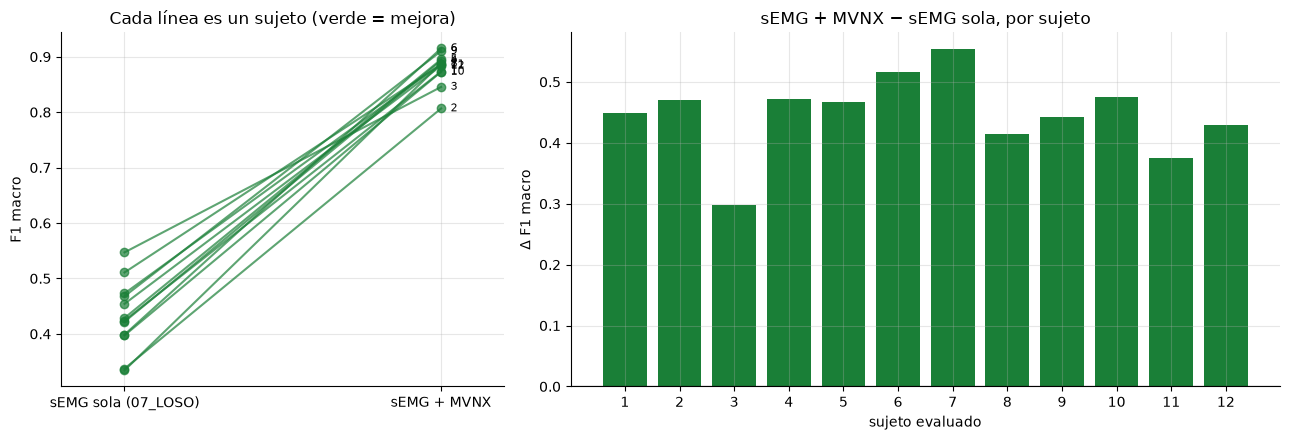

In [24]:
runs = [json.loads(p.read_text()) for p in sorted(RUN_DIR.glob("ronda_*.json"))]
assert runs, "Todavía no hay rondas terminadas."
fused = pd.DataFrame([{"sujeto": r["held_out"], "semilla": r["seed"], "F1": r["metrics"]["f1_macro"],
                       "bal_acc": r["metrics"]["balanced_accuracy"],
                       **{f"F1 {l}": f for l, f in zip(LABELS, r["metrics"]["f1_per_class"])}} for r in runs])
fused.to_csv(SUMMARY_CSV, index=False)
pairs = fused.merge(baseline[["sujeto", "semilla", "F1 ensayos sincronizados"]], on=["sujeto", "semilla"])
by_subject = (pairs.groupby("sujeto")[["F1 ensayos sincronizados", "F1"]].mean()
              .rename(columns={"F1 ensayos sincronizados": "sEMG sola (07_LOSO)", "F1": "sEMG + MVNX"}))
by_subject["diferencia"] = by_subject["sEMG + MVNX"] - by_subject["sEMG sola (07_LOSO)"]
summary = pd.DataFrame({"media": by_subject.mean(), "desv. entre sujetos": by_subject.std(),
                        "mínimo": by_subject.min(), "máximo": by_subject.max()}).T
print(f"Rondas terminadas: {len(runs)} | semillas: {sorted(map(int, fused['semilla'].unique()))}")
display(pd.concat([by_subject, summary]).round(3))

diff = by_subject["diferencia"].to_numpy()
boot = np.array([np.random.default_rng(SEED_DATA + b).choice(diff, len(diff)).mean() for b in range(5000)])
p = wilcoxon(diff).pvalue if len(diff) >= 5 and np.any(diff != 0) else np.nan
display(pd.DataFrame([{"comparación": "sEMG + MVNX − sEMG sola", "diferencia media": diff.mean(),
                       "IC 95 %": f"[{np.quantile(boot, .025):+.3f}, {np.quantile(boot, .975):+.3f}]",
                       "sujetos en que gana": f"{int((diff > 0).sum())} de {len(diff)}", "p (Wilcoxon)": p}])
        .set_index("comparación").round({"diferencia media": 3, "p (Wilcoxon)": 4}))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1, 1.6]})
a, b = "sEMG + MVNX", "sEMG sola (07_LOSO)"
for s in by_subject.index:
    axes[0].plot([0, 1], [by_subject.loc[s, b], by_subject.loc[s, a]], marker="o",
                 color="#1a7f37" if by_subject.loc[s, a] > by_subject.loc[s, b] else "#c0392b", alpha=0.7)
    axes[0].text(1.03, by_subject.loc[s, a], str(s), va="center", fontsize=8)
axes[0].set(xticks=[0, 1], xticklabels=[b, a], xlim=(-0.2, 1.2), ylabel="F1 macro",
            title="Cada línea es un sujeto (verde = mejora)")
axes[1].bar(by_subject.index.astype(str), by_subject["diferencia"],
            color=np.where(by_subject["diferencia"] > 0, "#1a7f37", "#c0392b"))
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set(xlabel="sujeto evaluado", ylabel="Δ F1 macro", title="sEMG + MVNX − sEMG sola, por sujeto")
plt.tight_layout()
plt.show()

# 11. Desempeño por actividad

Se juntan las predicciones de todos los sujetos evaluados y se calcula el F1 por actividad para los dos modelos, con la misma semilla y los mismos sujetos. La pregunta principal es si MVNX ayuda en las actividades que la sEMG confundía (PT, LT, W y PF).

,N,LF,K,PT,LT,W,PF,F1 macro
sEMG sola (07_LOSO),0.710,0.411,0.484,0.372,0.398,0.371,0.381,0.447
sEMG + MVNX,0.924,0.882,0.891,0.823,0.825,0.937,0.901,0.883
diferencia,0.214,0.471,0.407,0.451,0.427,0.566,0.520,0.437


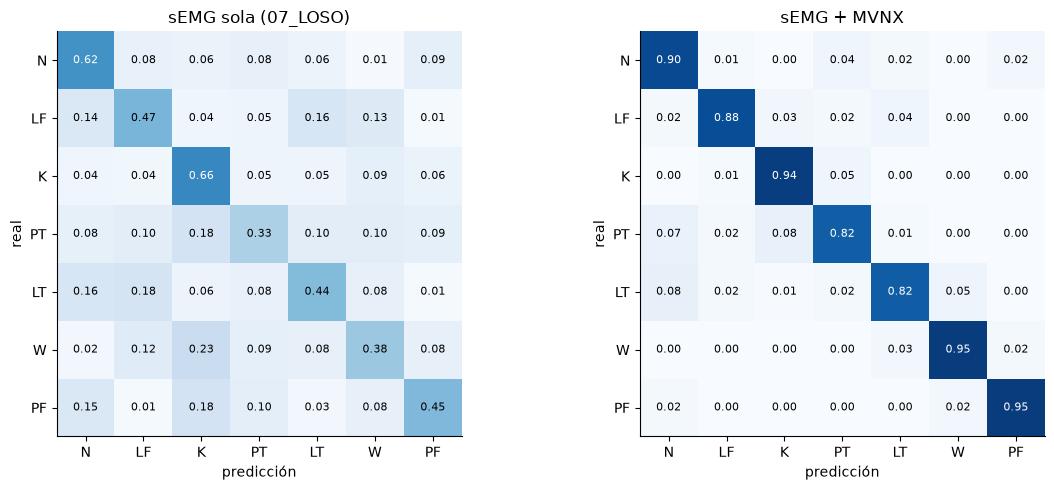

In [25]:
done = set(zip(fused["sujeto"], fused["semilla"]))
y_f = np.concatenate([r["y"] for r in runs]); p_f = np.concatenate([r["pred"] for r in runs])
base_done = baseline[[(s, k) in done for s, k in zip(baseline["sujeto"], baseline["semilla"])]]
y_b = np.concatenate(base_done["y"].to_list()); p_b = np.concatenate(base_done["pred"].to_list())
ids = range(len(LABELS))
per_class = pd.DataFrame({"sEMG sola (07_LOSO)": f1_score(y_b, p_b, labels=ids, average=None, zero_division=0),
                          "sEMG + MVNX": f1_score(y_f, p_f, labels=ids, average=None, zero_division=0)}, index=LABELS).T
per_class["F1 macro"] = per_class.mean(axis=1)
per_class.loc["diferencia"] = per_class.loc["sEMG + MVNX"] - per_class.loc["sEMG sola (07_LOSO)"]
display(per_class.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, y, pr) in zip(axes, (("sEMG sola (07_LOSO)", y_b, p_b), ("sEMG + MVNX", y_f, p_f))):
    cm = confusion_matrix(y, pr, labels=list(ids)).astype(float)
    cm /= cm.sum(axis=1, keepdims=True)
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    ax.set(xticks=list(ids), xticklabels=LABELS, yticks=list(ids), yticklabels=LABELS, xlabel="predicción", ylabel="real", title=name)
    ax.grid(False)
    for i in ids:
        for j in ids:
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if cm[i, j] > 0.55 else "black")
plt.tight_layout()
plt.show()

# 12. Sensibilidad: ensayos marcados y tipo de tarea

El 07_Sincronizacion conservó, pero **marcó** (`validacion_dudosa`), los ensayos en los que la correlación entre la sEMG y el movimiento no confirmó el desfase estimado con las etiquetas. Si la mejora con MVNX se debiera a un error de alineación, aparecería distinta en esos ensayos. La tabla recalcula el F1 macro de las predicciones juntas de todos los sujetos, para:

- todas las ventanas;
- sólo las de ensayos no marcados;
- sólo las de ensayos marcados;
- cada tipo de tarea.

No se reentrena nada.

In [26]:
trial_info = trials.set_index("trial_idx")
win_f = trial_info.loc[sup_index.loc[np.concatenate([r["index"] for r in runs]), "trial_idx"].to_numpy(), ["task", "validacion_dudosa"]]
win_b = trials.set_index("file").loc[np.concatenate(base_done["file"].to_list()), ["task", "validacion_dudosa"]]
subsets = {"todas": lambda w: np.ones(len(w), bool), "ensayos no marcados": lambda w: ~w["validacion_dudosa"].to_numpy(),
           "ensayos marcados": lambda w: w["validacion_dudosa"].to_numpy(),
           **{f"tarea {t}": (lambda w, t=t: (w["task"] == t).to_numpy()) for t in ("Isokin", "MMH_One", "MMH_Bim")}}
rows_12 = []
for name, sel in subsets.items():
    mf, mb = sel(win_f), sel(win_b)
    rows_12.append({"subconjunto": name, "ventanas": int(mf.sum()),
                    "sEMG sola (07_LOSO)": f1_score(y_b[mb], p_b[mb], average="macro") if mb.any() else np.nan,
                    "sEMG + MVNX": f1_score(y_f[mf], p_f[mf], average="macro") if mf.any() else np.nan})
sens = pd.DataFrame(rows_12).set_index("subconjunto")
sens["diferencia"] = sens["sEMG + MVNX"] - sens["sEMG sola (07_LOSO)"]
display(sens.round(3))

,ventanas,sEMG sola (07_LOSO),sEMG + MVNX,diferencia
subconjunto,,,,
todas,51814,0.447,0.883,0.437
ensayos no marcados,42398,0.460,0.883,0.423
ensayos marcados,9416,0.386,0.886,0.500
tarea Isokin,12894,0.283,0.664,0.381
tarea MMH_One,16250,0.441,0.896,0.455
tarea MMH_Bim,22670,0.446,0.883,0.437


# 13. Cómo leer los resultados

- **¿Ayuda MVNX?** Tabla de la sección 10. Es una mejora establecida si el intervalo de confianza no incluye el 0, la ventaja se repite en la mayoría de los 12 sujetos y p < 0.05. Con una sola semilla, conviene confirmar diferencias pequeñas (menos de unos 0.02) con la semilla 1 y re-ejecutando la sEMG sola en la rejilla sincronizada (sección 5).
- **¿Dónde ayuda?** Sección 11. Si la hipótesis del 07_LOSO es correcta, la mejora debe concentrarse en las actividades que dependen de la postura y del desplazamiento (PT, LT, W y PF), más que en N o K.
- **¿Es confiable?** Sección 12. Si la mejora es similar en los ensayos marcados y en los no marcados, no depende de los posibles errores de alineación.
- **Siguientes pasos si la prueba es positiva:**
  1. agregar la semilla 1;
  2. probar **MVNX sola**, para separar el aporte de cada modalidad;
  3. comparar la fusión temprana con una fusión tardía (un encoder por modalidad);
  4. sólo al final, abrir la prueba con los sujetos 13 y 14.